# Isolement des communes françaises : mesure de distance et cartorgraphie

**Question.** Quelles communes de France métropolitaine sont les plus éloignées des services du quotidien ?

### Plan

| # | Étape | Procédé |
|---|---|---|
| 0 | Mise en place | imports, chemins, paramètres |
| 1 | Données | fichiers INSEE téléchargés, fichiers manuels repérés |
| 2 | Nettoyage de la BPE | `data/interim/equipements.parquet` |
| 3 | Table des communes | une ligne par commune ou arrondissement : centre, surface, population, densité |
| 4 | Présence des services | tableau commune × service (vrai / faux) |
| 5 | Distances | tableau commune × service, en km |
| 6 | Table finale | `data/processed/communes_distances.parquet` |
| 7 | Indice d'isolement | quatre jeux de poids, trois variantes pour mesure de robustesse |
| 8 | Statistiques descriptives | tableaux et graphiques |
| 9 | Cartes | indice et six services |

## 0. Mise en place

1. Importation des bibliothèques (`pandas` pour les tableaux, `numpy` pour le calcul, `matplotlib` pour les graphiques).
2. Importe des modules : `download`, `prepare_bpe`, `communes`, `distances`, `indice`, `descriptif` qui sont dans le dossier src.
3. Définitions des chemins `data/raw`, `data/interim`, `data/processed` et le dossier `figures/`.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. On determine la racine du projet pour avoir accès aux autres dossiers et fichiers 
RACINE = Path.cwd()
if not (RACINE / "src").exists():
    raise FileNotFoundError("Lancez Jupyter depuis la racine du projet (le dossier qui contient src/).")
sys.path.insert(0, str(RACINE / "src"))

# 2. Les différents modules du dossiers src
import communes as cm
import descriptif as dsc
import distances as dist
import download
import indice as idx
import prepare_bpe

# 3. Chemins
RAW = RACINE / "data" / "raw" # Pour les bases brutes telechargées 
INTERIM = RACINE / "data" / "interim" # Pour les bases brutes après nettoyage et traitement
PROCESSED = RACINE / "data" / "processed" # Pour la base finale après la fusion
FIGURES = RACINE / "figures"
for dossier in (RAW, INTERIM, PROCESSED, FIGURES):
    dossier.mkdir(parents=True, exist_ok=True) # Pour créer les dossiers precedents dans les cas où ils n'existent pas 
    
# exist_ok=True c'sest pour une rien faire dans le cas où le dossier existe deja, parents=True pour ne pas recréer le dossier parent s'il existe deja  

# 4. Paramètres de l'analyse
SEUILS_KM = [5, 10, 20]      # On l'a chosit arbitrairement mais on peut les changer au cas où               
QUALITES_FIABLES = ["A", "B"]  # cf la variable QUALITE_XY             
SERVICES_CARTES = ["pharmacie", "medecin", "boulangerie", "ecole", "urgences", "gare"] # Ce sont les 6 services principales 
#qu'on representera pour pas que la carte soit touffue (vu qu'au total c'est 19services et ca peut faire trop sinon)
INDICE_PRINCIPAL = "egaux" # C'est notre baseline (poids égaux des differents services)                 

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 60) # Comme les tableaux seront très longs, ici on decide 
# d'afficher au max 200 caractères de large, 40 colonnes, 60 lignes 
print("Racine du projet :", RACINE)

C:\Users\USER\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\USER\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Racine du projet : C:\Users\USER\isolement-communes


## 1. Données

### 1.1 Téléchargement automatique des fichiers INSEE

**Objectif.** Récupérer les 5 fichiers INSEE (la BPE 2025 et sa documentation). Pour chaque fichier : saute s'il est déjà présent, sinon le télécharge par blocs vers un fichier temporaire, puis vérifie qu'il s'agit bien d'un parquet ou d'un CSV.

Ainsi, à la fin de ce code, on aura les fichiers : `BPE25.parquet`, `TYPEQU_2025.csv`, `BPE25_dessin_fichier.csv`, `BPE25_varmod.csv`, `BPE25_table_passage.csv` dans le dossier `data/raw/`.

Par ailleurs, on telecharge le reste des fichiers aussi qui nous servirons pour l'étude de nos corrélations, à savoir:

| Fichier | Utilité |
|---|---|
| **Contours des communes et arrondissements** (IGN Admin Express, édition COG 2025) | détermination des centres des communes, surfaces, cartes |
| **Population municipale 2023** (géographie 2025) |calcul de densité, part de la population éloignée |
| **Revenus Filosofi** (niveau commune) | lien isolement et revenu  |



In [2]:
download.main()

Téléchargements automatiques (INSEE, BPE 2025) :
- BPE25.parquet : La Base permanente des équipements 2025 : une ligne par équipement (médecin, école, boulangerie, gare...), avec son type, sa commune et sa position. Format parquet (colonnes compressées, ~163 Mo).
  déjà présent : BPE25.parquet
- TYPEQU_2025.csv : Le dictionnaire des types d'équipements : à chaque code (ex. D265) correspond un libellé (ex. médecin généraliste).
  déjà présent : TYPEQU_2025.csv
- BPE25_dessin_fichier.csv : Le « dessin de fichier » : la liste des colonnes de la BPE 2025 avec leur nom, leur type et leur longueur.
  déjà présent : BPE25_dessin_fichier.csv
- BPE25_varmod.csv : Le dictionnaire des variables et de leurs modalités : pour chaque colonne, les valeurs possibles et leur signification (ex. les niveaux de qualité de la géolocalisation).
  déjà présent : BPE25_varmod.csv
- BPE25_table_passage.csv : La table de passage domaine -> sous-domaine -> type d'équipement : elle range les types dans de grandes 

0

In [3]:
# On verifie que les fichiers sont bien là (dans le sous dossier RAW de data defini precedemment) où ils doivent être et leur taille aussi 
for element in sorted(RAW.iterdir()):
    if element.name.startswith("."):
        continue
    if element.is_dir():
        nombre = sum(1 for p in element.rglob("*") if p.is_file())
        print(f"[dossier] {element.name}  ({nombre} fichiers)")
    else:
        print(f"[fichier] {element.name}  ({element.stat().st_size / 1e6:.1f} Mo)")

[fichier] ADE-COG_4-0_GPKG_LAMB93_FXX-ED2025-01-01.gpkg  (1106.2 Mo)
[fichier] BPE25.parquet  (171.8 Mo)
[fichier] BPE25_dessin_fichier.csv  (0.0 Mo)
[fichier] BPE25_table_passage.csv  (0.0 Mo)
[fichier] BPE25_varmod.csv  (0.1 Mo)
[fichier] population.xlsx  (2.6 Mo)
[fichier] Revenus.csv  (40.1 Mo)
[fichier] TYPEQU_2025.csv  (0.1 Mo)


### 1.3 Les contours IGN

**Objectif.** Repérer les fichiers cartographiques d'Admin Express et choisir les deux couches dont on a besoin : **COMMUNE** et **ARRONDISSEMENT_MUNICIPAL**. (on parle bien d'arrondissement municipal (il n'y a que Paris, Lyon et Marseille qui sont subdivisés ainsi car trop grande, l'INSEE y range tous ses fichiers pour ces 3 communes en découpant direct en arrondissement municipal) et non pas d'arrondissements départementaux (qui eux regroupent plutot plusieurs communes, remember le classement region departement arrondissement commune)

Nous prenons ces deux niveaux car la BPE range les équipements de Paris, Lyon et Marseille **par arrondissement municipal** (par exemple une boulangerie du 3ᵉ arrondissement de Marseille a pour code `13203`) et pour le reste, c'est par commune. La couche COMMUNE contient ces trois villes d'un seul tenant (`75056`, `69123`, `13055`) : on prendra donc leurs arrondissements à leur place (car meme si pour eux on voulait considerer les communes, on trouverait 0 equipements associés ce qui est faux et c'est juste parceque les equipements ont été enregistrés au niveau arrondissement municipal pour éviter les doubles comptes).

In [4]:
CHEMIN_GPKG = RAW / "ADE-COG_4-0_GPKG_LAMB93_FXX-ED2025-01-01.gpkg"   # Ce fichier contient les contours des communes pour la cartographie                       
COUCHE_COMMUNES = "commune"                 
COUCHE_ARRONDISSEMENTS = "arrondissement_municipal"

if CHEMIN_GPKG is not None:
    print("Couches disponibles dans le GeoPackage :", cm.lister_couches(CHEMIN_GPKG))
    gdf_com = cm.lire_couche(CHEMIN_GPKG, COUCHE_COMMUNES)
    gdf_arm = cm.lire_couche(CHEMIN_GPKG, COUCHE_ARRONDISSEMENTS)
elif CHEMIN_SHP_COMMUNES is not None and CHEMIN_SHP_ARRONDISSEMENTS is not None: # Dans le cas où on a plutot un shapefile à la place (pour la reproductibilité)
    gdf_com = cm.lire_couche(CHEMIN_SHP_COMMUNES)
    gdf_arm = cm.lire_couche(CHEMIN_SHP_ARRONDISSEMENTS)
else:
    raise ValueError("Renseignez CHEMIN_GPKG")

print(f"\nCommunes : {len(gdf_com):,} lignes ; colonnes : {gdf_com.columns.tolist()}")
print(f"Arrondissements : {len(gdf_arm):,} lignes ; colonnes : {gdf_arm.columns.tolist()}")
print("Système de coordonnées :", gdf_com.crs) # Pour verifier que c'est bien le Lambert 93 (EPS 2154) de la France

C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'character varying' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'character varying(256)' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'character varying(30)' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\USER\anaconda3\Lib\site-packages\pyogrio\core.py:130: RuntimeWarning: Field format 'timestamp with time zone' not supported
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))


Couches disponibles dans le GeoPackage : ['canton', 'arrondissement', 'arrondissement_municipal', 'chef_lieu_d_arrondissement', 'chef_lieu_d_arrondissement_municipal', 'chef_lieu_de_canton', 'chef_lieu_de_collectivite_territoriale', 'chef_lieu_de_commune', 'chef_lieu_de_commune_associee_ou_deleguee', 'chef_lieu_de_departement', 'chef_lieu_d_epci', 'chef_lieu_de_region', 'collectivite_territoriale', 'commune', 'commune_associee_ou_deleguee', 'departement', 'epci', 'region', 'info_metadonnees', 'layer_styles']

Communes : 34,746 lignes ; colonnes : ['cleabs', 'nom_officiel', 'nom_officiel_en_majuscules', 'statut', 'code_insee', 'population', 'date_du_recensement', 'organisme_recenseur', 'code_insee_du_canton', 'code_insee_de_l_arrondissement', 'code_insee_du_departement', 'code_insee_de_la_region', 'code_siren', 'codes_siren_des_epci', 'code_postal', 'superficie_cadastrale', 'geometry']
Arrondissements : 45 lignes ; colonnes : ['cleabs', 'nom_officiel', 'nom_officiel_en_majuscules', 'num

### 1.4 La population

**Objectif.** Disposer de la population de chaque commune (et arrondissement) pour calculer la **densité** (habitants par km²) et la **part de la population éloignée** des services. Pour cela, nous utilisons le **Fichier INSEE « populations de référence »** de 2025.

*Pour y parvenir, la fonction `lire_tableau` lit un CSV ou un Excel en gardant tout en **texte**, pour ne pas perdre le zéro initial des codes. Si un fichier est indiqué, on affiche ses premières lignes.


In [5]:
%pip install --upgrade openpyxl

In [6]:
FICHIER_POPULATION = RAW / "population.xlsx"      
POP_OPTIONS = {"sheet_name": "Communes", "skiprows": 7} # On focus sur la feuille communes et comme les 7 premières lignes du fichier 
# sont des texte de présentation, et les vrais noms de colonne commencent à la ligne 8
POP_COL_CODE = "code_complet" # pour racoller les codes tels qu'ils sont dans les fichiers de l'INSEE 
# le code de l'INSEE pour la commune est tels que les 2 premiers sont ceux du département et les 3 autres celui de la commune
POP_COL_VALEUR = "Population municipale" # C'est la colonne qui contient le nombre d'habitants 

def lire_tableau(chemin, **options):
    if Path(chemin).suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(chemin, dtype=str, **options)
    # Else dans le cas d'un fichier csv 
    parametres = {"sep": None, "engine": "python"}
    parametres.update(options)
    return pd.read_csv(chemin, dtype=str, **parametres)

if FICHIER_POPULATION is not None:
    population_brute = lire_tableau(FICHIER_POPULATION, **POP_OPTIONS)
    print(population_brute.columns.tolist())
    display(population_brute.head())
else:
    print("Pas de fichier de population indiqué.")

# La colonne population comptée à part concerne des personnes qui ont des lien avec la commune mais n'y vivent pas à temps plein (
    #For eg, les personnes dont  les parents y vivent mais pas eux), 
# Donc pour eviter les doubles comptes, on considere plutot la population municipale pour les totaux, 
    # car si on fait des totaux en considerants les populations comptée à part, on fera des doubles comptes 

['Code région', 'Nom de la région', 'Code département', 'Code arrondissement', 'Code canton', 'Code commune', 'Nom de la commune', 'Population municipale', 'Population comptée à part', 'Population totale']


,Code région,Nom de la région,Code département,Code arrondissement,Code canton,Code commune,Nom de la commune,Population municipale,Population comptée à part,Population totale
0,84,Auvergne-Rhône-Alpes,01,2,08,001,L' Abergement-Clémenciat,860,16,876
1,84,Auvergne-Rhône-Alpes,01,1,01,002,L' Abergement-de-Varey,270,6,276
2,84,Auvergne-Rhône-Alpes,01,1,01,004,Ambérieu-en-Bugey,15934,405,16339
3,84,Auvergne-Rhône-Alpes,01,2,22,005,Ambérieux-en-Dombes,1906,24,1930
4,84,Auvergne-Rhône-Alpes,01,1,04,006,Ambléon,115,0,115


In [7]:
population_brute.columns = [" ".join(str(c).split()) for c in population_brute.columns] # Pour retirer des espaces inutiles
population_brute = population_brute.dropna(subset=["Code département", "Code commune"])
population_brute["code_complet"] = (population_brute["Code département"].str.strip().str.zfill(2)
                                    + population_brute["Code commune"].str.strip().str.zfill(3)) # Ajouter une colonne qui reconstitue le code complet de le commune
print(population_brute.columns.tolist()) # Nous nous assurons que la colonne code_commune est bien là
display(population_brute[["code_complet", "Nom de la commune", "Population municipale"]].head())
print(population_brute["code_complet"].str.len().value_counts()) # Verif du nombre de DROM et nombre de communes en France metropolitaine presente 

# Dans les results, les codes à 6 length sont les communes outre mer, elles serint éliminés lors de la jointure plus tard 

['Code région', 'Nom de la région', 'Code département', 'Code arrondissement', 'Code canton', 'Code commune', 'Nom de la commune', 'Population municipale', 'Population comptée à part', 'Population totale', 'code_complet']


,code_complet,Nom de la commune,Population municipale
0,01001,L' Abergement-Clémenciat,860
1,01002,L' Abergement-de-Varey,270
2,01004,Ambérieu-en-Bugey,15934
3,01005,Ambérieux-en-Dombes,1906
4,01006,Ambléon,115


code_complet
5    34788
6      116
Name: count, dtype: int64


## 2. Nettoyage de la BPE

### 2.1 Les 19 services : lesquels on mélange, et pourquoi

La BPE décrit **33 types d'équipements** (un code `TYPEQU` chacun). Pour mesurer l'isolement, on raisonne en **services** : un service correspond à un **besoin d'habitant**. Quand plusieurs types répondent au même besoin, on les **regroupe** : la commune est « équipée » dès qu'elle possède **au moins un** des types du service.

**10 services restent seuls** (un seul type) :

| Service | Type | Libellé BPE |
|---|---|---|
| boulangerie | B207 | boulangerie-pâtisserie |
| pharmacie | D307 | pharmacie |
| medecin | D265 | médecin généraliste |
| dentiste | D277 | chirurgien-dentiste |
| kine | D279 | masseur-kinésithérapeute |
| infirmier | D281 | infirmier |
| urgences | D106 | urgences |
| maternite | D107 | maternité |
| college | C201 | collège |
| france_services | A128 | France Services |

**9 services regroupent plusieurs types** :

| Service | Types mélangés | Pourquoi les mélanger |
|---|---|---|
| alimentation | B201 supérette, B202 épicerie, B105 supermarché et multi-commerce | trois formats pour faire ses courses de base |
| sante_proximite | D108 centre de santé, D113 maison de santé pluridisciplinaire | deux structures de soins de premier recours |
| ecole | C107 maternelle, C108 primaire, C109 élémentaire | même besoin : scolariser un jeune enfant |
| lycee | C301 général et technologique, C302 professionnel | même niveau d'enseignement |
| poste | A206 bureau de poste, A207 relais poste, A208 agence postale | trois formes de présence postale |
| petite_enfance | D502 accueil du jeune enfant, D509 micro-crèche | même besoin : faire garder un enfant |
| personnes_agees | D401 hébergement, D402 soins à domicile, D403 aide à domicile | **mélange discutable** : un lieu et des services qui se déplacent chez la personne |
| proximite_sociale | D506 centres sociaux, D508 espaces de vie sociale | deux lieux d'accueil social local |
| gare | E107 nationale, E108 régionale, E109 locale | même besoin : prendre le train |

Médecin, dentiste, kiné et infirmier restent séparés : ce sont des soins différents, qu'un habitant ne substitue pas l'un à l'autre.

Toutefois, 
1. **« Personnes âgées »** mélange des lieux (hébergement) et des services à domicile, pour lesquels la distance a un autre sens : une variante de l'indice l'exclut 
2. **La santé pèse 8 services sur 19**, soit 42 % d'un indice à poids égaux : un jeu de poids **équilibre les thèmes** 

Le dictionnaire `SERVICES` dans `src/prepare_bpe.py` est là où on définit ce panier. 

### 2.2 Filtrer la BPE sur le panier

**Objectif.** Passer des 2 921 770 lignes et 95 colonnes de la BPE à un fichier qui contient seulement les équipements du panier, en métropole, avec les 6 colonnes utiles.

**Entrées.** `data/raw/BPE25.parquet`.

**Ce que fait le code.** Appelle `prepare_bpe.main()` qui : (1) garde la métropole (`EPSG = 2154`, c'est-à-dire coordonnées Lambert-93) ; (2) garde les 33 types du panier ; (3) range chaque type dans son service ; (4) **conserve les équipements sans coordonnées** (ils servent à comptabiliser la présence la présence) ; (5) écrit `data/interim/equipements.parquet` et affiche un tableau de contrôle par service.

**Sorties.** `data/interim/equipements.parquet` : colonnes `depcom`, `service`, `typequ`, `x`, `y`, `qualite_xy`.


In [9]:
prepare_bpe.main()

531,417 équipements du panier en métropole -> C:\Users\USER\isolement-communes\data\interim\equipements.parquet
                   equipements  avec_xy  communes  part_avec_xy_%
service                                                          
infirmier                98143    98132     11684           100.0
kine                     88888    88862      9639           100.0
medecin                  59504    59496      8791           100.0
boulangerie              48344    46965     12614            97.1
ecole                    47140    47137     21219           100.0
alimentation             44812    44220     10368            98.7
dentiste                 39973    39952      5840            99.9
personnes_agees          21108    21101      6953           100.0
pharmacie                19724    19619      8090            99.5
petite_enfance           18331    18324      6584           100.0
poste                    16617    16617     13813           100.0
college                   7256

0

### 2.3 Charger et contrôler les équipements

**Objectif.** vérifier que le fichier est bien organisé.

**Ce que fait le code.**
1. Charge `equipements.parquet` dans un tableau `equipements` et dresse la liste `services` (les 19 noms, dans l'ordre du dictionnaire).
2. Contrôle que les 19 services sont bien présents.
3. Contrôle que **tous les codes commune font 5 caractères** (sinon une fusion échouera car ca veut dire que d'ne part, on aura encore considéré les DROM).
4. Affiche la répartition des qualités de position (`A`, `B`, `M`, `_U`, `_Z`) et la part d'équipements sans coordonnées.


In [10]:
equipements = pd.read_parquet(INTERIM / "equipements.parquet")
services = list(prepare_bpe.SERVICES)

assert set(equipements["service"]) == set(services), "Un service du panier n'a aucun équipement." # Assert verifie que nos conditions sont verifier 
assert (equipements["depcom"].str.len() == 5).all(), "Des codes commune ne font pas 5 caractères."

print(f"{len(equipements):,} équipements, {len(services)} services")
print("\nQualité de la position :")
print(equipements["qualite_xy"].value_counts(dropna=False))
print(f"\nSans coordonnées : {equipements['x'].isna().mean():.1%}") # Pour voir le poids des fichiers sans coordonnées qui est de 0.4%

531,417 équipements, 19 services

Qualité de la position :
qualite_xy
B     475609
M      30958
A      22686
_U      2164
Name: count, dtype: int64

Sans coordonnées : 0.4%


## 3. Table des communes

### 3.1 Extraire un centre, une surface et une population de chaque contour

**Objectif.** Concevoir un tableau qui donne à chaque commune (et arrondissement municipal pour le cas Paris, Lyon et Marseille), les distances, une surface et une population.

**Ce que fait le code.**
1. Repère les colonnes utiles de chaque couche par leur nom (code, nom, population) : les noms exacts varient selon l'édition, la fonction `choisir_colonne` essaie plusieurs noms possibles et les affiche.
2. Transforme chaque couche en tableau avec `geometrie_vers_table` : `code`, `nom`, `population`, `x` et `y` (le centroïde du polygone, en mètres Lambert-93), `surface_km2` (aire du polygone).
3. Pour les arrondissements municipaux, retient aussi la colonne commune correspondante.


In [11]:
# Colonnes utiles
col_code_com = cm.choisir_colonne(gdf_com.columns, ["code_insee", "insee_com", "codgeo"]) # Car les noms varient d'un fichier Insee à un autre (for eg chez nous ca s'appelle code_insee alors que dans d'autres ca peut être insee_com) 
col_nom_com = cm.choisir_colonne(gdf_com.columns, ["nom_officiel", "nom", "libgeo"], obligatoire=False)
col_pop_com = cm.choisir_colonne(gdf_com.columns, ["population", "pmun", "pop"], obligatoire=False)

col_code_arm = cm.choisir_colonne(gdf_arm.columns, ["code_insee", "insee_arm", "codgeo"])
col_parent_arm = cm.choisir_colonne(gdf_arm.columns, ["code_insee_de_la_commune_de_rattach", "insee_com"])
col_nom_arm = cm.choisir_colonne(gdf_arm.columns, ["nom_officiel", "nom", "libgeo"], obligatoire=False)
col_pop_arm = cm.choisir_colonne(gdf_arm.columns, ["population", "pmun", "pop"], obligatoire=False)

print("Communes        : code =", col_code_com, "| nom =", col_nom_com, "| population =", col_pop_com)
print("Arrondissements : code =", col_code_arm, "| ville mère =", col_parent_arm,
      "| nom =", col_nom_arm, "| population =", col_pop_arm)

tab_com = cm.geometrie_vers_table(gdf_com, col_code_com, col_nom_com, col_pop_com)
tab_arm = cm.geometrie_vers_table(gdf_arm, col_code_arm, col_nom_arm, col_pop_arm, col_parent_arm)
display(tab_com.head(3))
display(tab_arm.head(3))

Communes        : code = code_insee | nom = nom_officiel | population = population
Arrondissements : code = code_insee | ville mère = code_insee_de_la_commune_de_rattach | nom = nom_officiel | population = population


,code,nom,population,x,y,surface_km2
0,01001,L'Abergement-Clémenciat,859,848615.932409,6.563357e+06,15.619934
1,01002,L'Abergement-de-Varey,273,887854.436151,6.548429e+06,9.175479
2,01004,Ambérieu-en-Bugey,15554,883700.036196,6.542908e+06,24.508833


,code,nom,population,x,y,surface_km2,parent
0,13207,Marseille 7e Arrondissement,34866,890274.695843,6.245190e+06,5.704744,13055
1,75119,Paris 19e Arrondissement,178371,654888.615083,6.865402e+06,6.784887,75056
2,75118,Paris 18e Arrondissement,185825,652206.316949,6.866037e+06,5.995535,75056


### 3.2 Assembler la base : communes + arrondissements

**Objectif.** Obtenir une seule table, où Paris, Lyon et Marseille apparaissent par arrondissement (comme dans la BPE) et on a apres les autres communes.

**Ce que fait le code.** `cm.assembler_base` :
1. retire de la table des communes les villes mères ( Paris Marseille et Lyon dont les codes sont 75056, 13055, 6912) ;
2. ajoute les arrondissements ;
3. retire les départements d'outre-mer (codes commençant par `97` ou `98`) ;
4. vérifie que tous les codes font 5 caractères (etant donné qu'on a retiré les codes pour les outre mer qui faisaient 6 caractères) et qu'aucun code n'est en double ;
5. calcule la densité = population ÷ surface.


In [12]:
base = cm.assembler_base(tab_com, tab_arm)
villes_meres = set(tab_arm["parent"])

print("Villes remplacées par leurs arrondissements :", sorted(villes_meres))
assert villes_meres == {"75056", "13055", "69123"}, "Les villes mères ne sont pas Paris, Lyon et Marseille."

print(f"{len(base):,} communes (et arrondissements pour Lyon Paris et Marselle) en métropole")
print("Population manquante :", int(base["population"].isna().sum()))
display(base.describe().round(2))

Villes remplacées par leurs arrondissements : ['13055', '69123', '75056']
34,788 communes (et arrondissements pour Lyon Paris et Marselle) en métropole
Population manquante : 0


,population,x,y,surface_km2,densite
count,34788.00,34788.00,34788.00,34788.00,34788.00
mean,1892.79,685775.44,6653206.77,15.78,183.62
std,8683.08,201458.27,247707.48,17.30,978.44
min,0.00,103236.00,6057337.41,0.03,0.00
25%,197.00,531921.87,6446239.52,6.52,18.22
50%,457.00,679524.50,6700051.97,10.97,40.35
75%,1162.00,845883.38,6863147.53,18.99,96.92
max,511684.00,1238789.55,7108700.31,757.08,38343.42


### 3.3 Population : fichier INSEE 

**Objectif.** Remplacer la population des contours par la population municipale 2023.

**Ce que fait le code.** Si `FICHIER_POPULATION` est renseigné, `cm.fusionner_population` fait une jointure à gauche sur le code commune : les codes du fichier sont remis sur 5 caractères en texte, et la densité est recalculée. Les communes de la base sans population dans le fichier, et les codes du fichier absents de la base. Sinon, on garde la population des contours.


In [13]:
if FICHIER_POPULATION is not None:
    base, journal = cm.fusionner_population(base, population_brute, POP_COL_CODE, POP_COL_VALEUR)
    print("Journal de la fusion de la population :", journal)
else:
    print("Population des contours IGN conservée.")

print("Population manquante après fusion :", int(base["population"].isna().sum()))
print(f"Population totale de la base : {base['population'].sum():,.0f} habitants")

Journal de la fusion de la population : {'communes_base': 34788, 'communes_sans_population_ext': 0, 'codes_ext_hors_base': 116}
Population manquante après fusion : 0
Population totale de la base : 66,165,815 habitants


### 3.4 Polygones pour les cartes, et lien avec la BPE

**Objectif.** Préparer les polygones qui serviront aux cartes et vérifier que les codes de la BPE et ceux de la base se correspondent.

**Ce que fait le code.**
1. `cm.geometries_base` construit les polygones de la base (communes sans les trois villes mères, plus les arrondissements) et on contrôle qu'ils portent exactement les mêmes codes que `base`.
2. `dist.controle_codes` compte les équipements dont le code commune est **inconnu** de la base (il ne doit pas en avoir, c'est pour verifier). On compte aussi les communes de la base sans aucun équipement du panier.

[Les communes sans aucun équipement du panier sont normales (petits villages) : elles auront simplement de grandes distances partout, lors du calcul de distance]

In [14]:
geo = cm.geometries_base(gdf_com, gdf_arm, col_code_com, col_code_arm, villes_meres)
assert set(geo["code"]) == set(base["code"]), "Les polygones et la table de base n'ont pas les mêmes codes."

print("Codes BPE absents de la base :", dist.controle_codes(equipements, base["code"]))
sans_equipement = ~base["code"].isin(equipements["depcom"])
print(f"Communes sans aucun équipement du panier : {int(sans_equipement.sum()):,} sur {len(base):,}")

Codes BPE absents de la base : {'equipements_sans_commune': 0, 'codes_inconnus': []}
Communes sans aucun équipement du panier : 10,806 sur 34,788


## 4. Présence des services

**Objectif.** Savoir, pour chaque commune et chaque service, si au moins un équipement du service se trouve dans la commune. (Remember la règle de distance : service présent → distance 0).
**Ce que fait le code.** `dist.presence_par_service` crée un tableau de booléens (une ligne par commune, une colonne par service), initialement tout à `False`, puis met `True` aux couples (commune, service) qui existent dans la BPE.
**Sorties.** `presence` : tableau commune × service.On comptabilise la porportion de communes ayant un service donné.

L'ordre de grandeur attendu : élevé pour la boulangerie, l'école ou le médecin, faible pour les urgences, la maternité, les gares et le lycée. Si un service affiche 0 % ou 100 %, il y a un problème car ca signifierait que le service n'existe nulle part pour le 0% et pour le 100%, ca voudrait dire que toutes les communes ont le service en question.

In [15]:
presence = dist.presence_par_service(base["code"], equipements, services)
part_equipees = (presence.mean() * 100).round(1).sort_values()
display(part_equipees.to_frame("communes équipées (%)"))

,communes équipées (%)
maternite,1.1
urgences,1.6
lycee,4.3
france_services,7.1
proximite_sociale,7.2
gare,7.4
sante_proximite,9.9
college,11.1
dentiste,16.8
petite_enfance,18.9


## 5. Distances au service le plus proche

**Objectif.** Calculer, pour chaque commune et chaque service, la distance (en km) à laquelle il faut aller pour trouver le service.

La règle utilisée ici est la suivante:
1. Service présent dans la commune → distance 0.
2. Sinon → distance à vol d'oiseau entre le centre de la commune et l'équipement le plus proche qui a des coordonnées. On ne garde que la plus petite des distances : on n'additionne ni ne moyenne les équipements.

**Ce que fait le code.** Pour chacun des 19 services, `dist.distances_par_service` :
1. rassemble les équipements du service qui ont des coordonnées ;
2. construit un **arbre k-d** (`cKDTree` de SciPy) avec leurs positions : cette structure range les points dans l'espace pour trouver le plus proche sans tout comparer (sinon ca ferait 35 000 communes × 550 000 équipements représenteraient près de 20 milliards de comparaisons) ;
3. interroge l'arbre avec le centre de chaque commune : on obtient la distance en mètres au plus proche, convertie en **kilomètres** ;
4. remplace par **0** les distances des communes où le service est présent.

**Sorties.** `distances` : tableau commune × service en km (index = code commune), et `presence`.


In [16]:
distances, presence = dist.distances_par_service(base, equipements, services)

manquantes = distances.isna().sum() #repère les cases vides, et .sum() les compte par service.
print("Distances manquantes par service :", manquantes[manquantes > 0].to_dict() or "aucune")
assert (distances[presence].fillna(0) == 0).all().all(), "Une commune équipée a une distance non nulle."

display(dsc.resume_par_service(distances))

# For the results, remember que les colonnes signifient: 
#commune_equipees = part des communes qui ont le service et donc dist=0
# mediane km= distance mediane pour les differentes communes pour le service en question 
# (mediane=dist telle que la moitié des comm est plus proche et l'autre moitié plus loin
#q90km= 9 communes sur 10 sont à moins de cette distance )1% est plus loin
# q99km= 99% des communes sont à moins de cette distance + 99e centiles

Distances manquantes par service : aucune


,communes_equipees_%,mediane_km,moyenne_km,q90_km,q99_km,max_km
maternite,1.1,17.99,19.08,32.81,46.93,79.08
urgences,1.6,14.04,14.75,25.10,34.75,53.05
lycee,4.3,9.66,10.47,18.91,27.69,42.12
france_services,7.1,6.28,6.43,10.79,15.26,24.64
proximite_sociale,7.2,7.09,7.73,14.17,21.63,42.71
gare,7.4,8.35,10.16,21.11,33.82,63.82
sante_proximite,9.9,5.92,6.29,11.34,17.80,28.51
college,11.1,5.43,5.66,10.10,15.67,35.19
dentiste,16.8,4.87,5.15,9.97,15.76,26.76
petite_enfance,18.9,4.68,5.06,10.19,16.51,25.14


## 6. Table finale

**Objectif.** Rassembler en une table, une ligne par commune, tout ce qui sert à l'analyse :code commune, nom, surface, population, densité et les 19 distances. C'est le tableau de référence pour la suite du projet.

**Ce que fait le code.**
1. Joint les distances à la base sur le code commune (`base.set_index("code").join(distances)`).
2. Enregistre la table et le tableau de présence au format parquet dans `data/processed/`.

**Sorties.** `data/processed/communes_distances.parquet` et `data/processed/communes_presence.parquet`.


In [17]:
table = base.set_index("code").join(distances)
assert len(table) == len(base)

table.reset_index().to_parquet(PROCESSED / "communes_distances.parquet", index=False)
presence.reset_index().to_parquet(PROCESSED / "communes_presence.parquet", index=False)

print(f"Table finale : {table.shape[0]:,} lignes, {table.shape[1]} colonnes")
display(table.head())

Table finale : 34,788 lignes, 25 colonnes


,nom,population,x,y,surface_km2,densite,boulangerie,alimentation,pharmacie,medecin,dentiste,kine,infirmier,sante_proximite,urgences,maternite,ecole,college,lycee,poste,france_services,petite_enfance,personnes_agees,proximite_sociale,gare
code,,,,,,,,,,,,,,,,,,,,,,,,,
01001,L'Abergement-Clémenciat,860,848615.932409,6.563357e+06,15.619934,55.057851,3.610229,4.159714,4.145357,4.038694,3.708040,4.357451,4.038694,4.038694,19.944508,19.944508,0.000000,4.010667,4.073329,4.652302,4.249970,4.249970,3.875613,4.933852,9.610277
01002,L'Abergement-de-Varey,270,887854.436151,6.548429e+06,9.175479,29.426256,3.664020,3.585880,3.867564,3.620826,3.679402,3.808524,3.679402,5.387768,6.803027,6.803027,3.519712,7.541495,7.133485,3.513149,6.791859,4.010997,3.513955,6.791859,6.947928
01004,Ambérieu-en-Bugey,15934,883700.036196,6.542908e+06,24.508833,650.132960,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
01005,Ambérieux-en-Dombes,1906,847969.142107,6.545839e+06,16.014205,119.019335,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.053338,15.883473,15.883473,0.000000,8.475689,12.803361,0.000000,10.016482,5.497179,0.000000,8.368672,7.178552
01006,Ambléon,115,901679.429189,6.520012e+06,6.030856,19.068603,3.383037,4.741154,4.579328,4.579328,7.454663,6.943758,4.657698,8.414845,6.636751,6.636751,3.216755,7.114515,7.114515,4.621853,6.862438,6.741431,4.022882,6.862438,11.982646


## 7. L'indice d'isolement

### 7.1 Principe

On dispose de 19 distances par commune, qu'on veut **résumer en un seul chiffre** : l'indice d'isolement. On ne peut pas additionner directement les kilomètres : un service rare (maternité) a de grandes distances partout et écraserait un service fréquent (infirmier) dont les distances sont toutes petites.

**Les trois étapes.**
1. **Logarithme** : `d' = ln(1 + d)`, avec `d` en km. Il atténue les distances extrêmes pour la standardisation. Le « +1 » permet de traiter les distances nulles (service présent).
2. **Standardisation** (z-score), **service par service** : `z = (d' − moyenne du service) / écart-type du service`, calculés sur l'ensemble des communes. Chaque service est ramené à la même échelle. Un `z` de +1 signifie « un écart-type plus loin que la moyenne des communes pour ce service ». Et donc du fait de cette standardisation, l’indice mesure donc l’isolement relatif de chaque commune par rapport aux autres communes.
3. **Somme pondérée** : `I = Σ(w × z) / Σ(w)`. Plus l'indice est élevé, plus la commune est isolée. Diviser par la somme des poids garde la même échelle quel que soit le jeu de poids. Et ka methodologie de calcul de poids dependra du jeu de poids considéré.

*Remarque.* Chaque commune compte pour une unité dans le calcul de la moyenne et de l'écart-type, quelle que soit sa population. 

### 7.2 Les jeux de poids

| Jeu | Définition | Question à laquelle il répond |
|---|---|---|
| `egaux` | tous les services pèsent 1 | indice de référence |
| `vitaux` | urgences, maternité, médecin, pharmacie, santé de proximité comptent double | et si les soins de premier recours et urgents pèsent plus ? |
| `themes` | chaque thème (commerces, santé, enseignement, services publics, transport) pèse autant | et si la santé (8 services) ne dominait pas ? |
| `acp` | première composante principale des 19 `z` | que dit la structure des données elle-même ? |

L'**ACP** (analyse en composantes principales) trouve la combinaison des 19 `z` qui varie le plus d'une commune à l'autre. Son signe est arbitraire : on l'oriente pour qu'un score élevé veuille dire « plus isolé ».


In [18]:
z = idx.standardiser(idx.log_distance(distances))

poids = {
    "egaux": idx.poids_egaux(services),
    "vitaux": idx.poids_vitaux(services),
    "themes": idx.poids_themes_equilibres(services),
}
indices = pd.DataFrame({nom: idx.indice_pondere(z, p) for nom, p in poids.items()})
indices["acp"], part_pc1 = idx.indice_acp(z, indices["egaux"])

print(f"Part de la variance expliquée par la 1re composante (ACP) : {part_pc1:.1%}")
display(pd.DataFrame(poids).round(2).T)
display(indices.describe().round(3))

Part de la variance expliquée par la 1re composante (ACP) : 51.6%


,boulangerie,alimentation,pharmacie,medecin,dentiste,kine,infirmier,sante_proximite,urgences,maternite,ecole,college,lycee,poste,france_services,petite_enfance,personnes_agees,proximite_sociale,gare
egaux,1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,1.0
vitaux,1.0,1.0,2.00,2.00,1.00,1.00,1.00,2.00,2.00,2.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.0,1.0
themes,0.5,0.5,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.33,0.33,0.33,0.2,0.2,0.2,0.2,0.2,1.0


,egaux,vitaux,themes,acp
count,34788.000,34788.000,34788.000,34788.000
mean,-0.000,-0.000,0.000,0.000
std,0.712,0.715,0.702,3.131
min,-2.160,-2.309,-2.086,-8.968
25%,-0.414,-0.413,-0.410,-1.852
50%,0.161,0.166,0.129,0.752
75%,0.522,0.522,0.516,2.299
max,1.786,1.816,1.706,7.842


### 7.3 Robustesse : trois variantes

**Objectif.** On teste ici la robustesse des calculs precedents. On recalcule l'indice (à poids égaux) en changeant une chose à la fois :

| Variante | Ce qui change | Choix testé |
|---|---|---|
| `sans_pers_agees` | on retire le service « personnes âgées » car pour ce groupe, on fait les soins à domicile et donc la distance n'a pas really d'intéret here | La règle « service présent dans la commune, distance 0 » ne traduit donc pas bien la réalité de ces services |
| `positions_AB` | seules les positions de qualité A et B servent aux distances | la fiabilité des coordonnées (la présence reste inchangée) |
| `sans_regle_presence` | la distance est toujours mesurée depuis le centre de la commune, même si le service est dans la commune | la règle « présent = 0 » |

**Comment on compare.** Par la **corrélation de Spearman** entre les indices : elle compare les **classements** des communes (on mesure la correlation entre les classements suivant les differents indices). Elle vaut 1 si deux indices classent les communes dans le même ordre. En règle générale, une valeur supérieure à 0,9 indique des classements très proches.

**Ce que fait le code.** Calcule les trois variantes, ajoute leurs colonnes à `indices`, puis affiche la **matrice de Spearman** sous forme de tableau coloré et l'enregistre en figure.


Distances manquantes avec A/B seulement : 0


,egaux,vitaux,themes,acp,sans_pers_agees,positions_AB,sans_regle_presence
egaux,1.000,0.996,0.979,0.999,0.999,0.996,0.963
vitaux,0.996,1.000,0.968,0.995,0.995,0.992,0.964
themes,0.979,0.968,1.000,0.974,0.979,0.976,0.941
acp,0.999,0.995,0.974,1.000,0.997,0.995,0.961
sans_pers_agees,0.999,0.995,0.979,0.997,1.000,0.995,0.962
positions_AB,0.996,0.992,0.976,0.995,0.995,1.000,0.959
sans_regle_presence,0.963,0.964,0.941,0.961,0.962,0.959,1.000


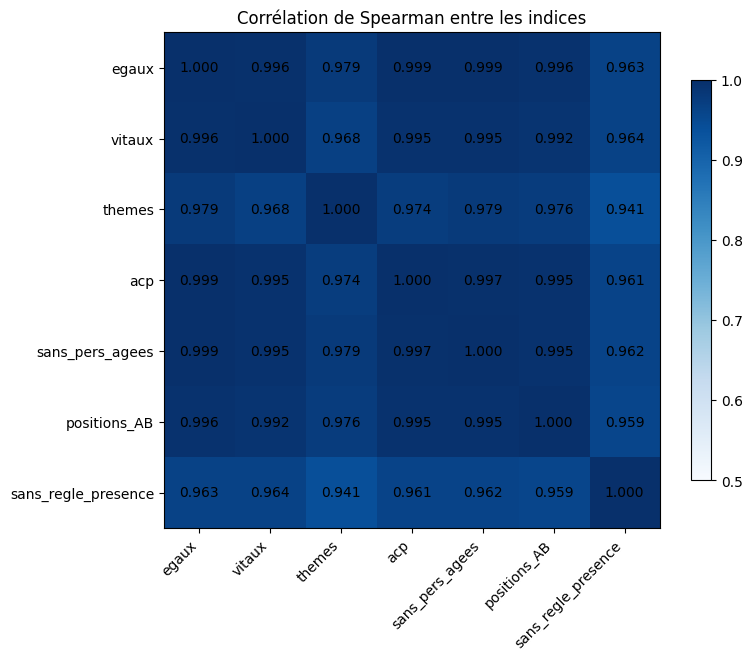

In [19]:
# Variante 1 : sans « personnes âgées »
services_sans_pa = [s for s in services if s != "personnes_agees"]
indices["sans_pers_agees"] = idx.indice_pondere(z[services_sans_pa], idx.poids_egaux(services_sans_pa))

# Variante 2 : positions de qualité A et B seulement (la présence n'est pas filtrée)
distances_ab, _ = dist.distances_par_service(base, equipements, services, qualites=QUALITES_FIABLES)
print("Distances manquantes avec A/B seulement :", int(distances_ab.isna().sum().sum()))
indices["positions_AB"] = idx.calculer_indice(distances_ab, idx.poids_egaux(services))

# Variante 3 : sans la règle « présent = 0 », et on calcule toujorus par rapport au centre de la commune
distances_sans, _ = dist.distances_par_service(base, equipements, services, regle_presence=False)
indices["sans_regle_presence"] = idx.calculer_indice(distances_sans, idx.poids_egaux(services))

rho = idx.comparer_classements(indices)
display(rho.round(3))

fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(rho, vmin=min(0.5, float(rho.values.min())), vmax=1, cmap="Blues")
ax.set_xticks(range(len(rho)))
ax.set_xticklabels(rho.columns, rotation=45, ha="right")
ax.set_yticks(range(len(rho)))
ax.set_yticklabels(rho.index)
for i in range(len(rho)):
    for j in range(len(rho)):
        ax.text(j, i, f"{rho.iloc[i, j]:.3f}", ha="center", va="center", color="black")
ax.set_title("Corrélation de Spearman entre les indices")
fig.colorbar(image, shrink=0.8)
fig.savefig(FIGURES / "robustesse_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

indices.reset_index().to_parquet(PROCESSED / "indices.parquet", index=False)

On remarque que le classement est très stable. Toutes les corrélations sont supérieures ou égales à **0,941**. La plupart dépassent 0,99. 

**1. Les jeux de poids** (egaux, vitaux, themes, acp) :
- `egaux` et `acp` sont presque identiques (**0,999**) : les poids que l'ACP trouve dans les données sont proches de poids égaux. Cela s'accorde avec le fait qu'une seule composante explique 51,6 % de la variance : les 19 distances évoluent ensemble.
- `vitaux` reste très proche de `egaux` (**0,996**) : doubler cinq services de santé et d'urgence change peu le classement.
- `themes` est le jeu le plus éloigné (**0,979** avec `egaux`, **0,968** avec `vitaux`). C'est logique : il réduit fortement le poids de chacun des huit services de santé (0,125 contre 1) et augmente celui de la gare (1,0).

**2. Les choix sur les données** :
- Retirer le service « personnes âgées » (`sans_pers_agees`) ne change rien (**0,999**) : le mélange discutable avec les services à domicile n'influence pas les résultats.
- Ne garder que les positions de qualité A et B (`positions_AB`) donne **0,996** : les coordonnées de moindre qualité ne faussent pas le classement.

**3. La règle de distance** : `sans_regle_presence` est la variante la plus éloignée de toutes (0,941 à 0,964). C'est le seul choix qui modifie la définition de la distance : une commune qui possède un service n'est plus à distance 0, mais à distance de son centre au service le plus proche. Même ainsi, la corrélation reste supérieure à 0,94.

Les poids, la qualité des positions et le service le plus contestable ont un effet négligeable sur le classement. La règle « présent = 0 » est le choix le plus influent, sans changer l'essentiel. Nos résultats ne dépendent donc pas de ces décisions. Nous gardons `egaux` comme indice de référence.


## 8. Statistiques descriptives

### 8.1 Les distances, service par service

**Objectif.** Décrire la distribution des distances : combien de communes sont équipées, quelle est la distance médiane, que se passe-t-il dans les cas extrêmes ?

**Ce que fait le code.** Affiche, pour chaque service, la **part de communes équipées**, la **médiane**, la **moyenne**, le 90ᵉ et le 99ᵉ **centile** (la distance au-delà de laquelle se trouvent les 10 % et 1 % de communes les plus éloignées) et le **maximum**. On compare médiane et moyenne : si la moyenne est bien plus grande, quelques communes très éloignées tirent vers le haut (hypothèse H1 : distribution très asymétrique).

Puis un boxplot par service, sur l'échelle `ln(1 + d)`, triés par médiane. la ligne centrale est la médiane, les points sont les cas extrêmes hors de la boites à moustache .


,communes_equipees_%,mediane_km,moyenne_km,q90_km,q99_km,max_km
maternite,1.1,17.99,19.08,32.81,46.93,79.08
urgences,1.6,14.04,14.75,25.10,34.75,53.05
lycee,4.3,9.66,10.47,18.91,27.69,42.12
gare,7.4,8.35,10.16,21.11,33.82,63.82
proximite_sociale,7.2,7.09,7.73,14.17,21.63,42.71
france_services,7.1,6.28,6.43,10.79,15.26,24.64
sante_proximite,9.9,5.92,6.29,11.34,17.80,28.51
college,11.1,5.43,5.66,10.10,15.67,35.19
dentiste,16.8,4.87,5.15,9.97,15.76,26.76
petite_enfance,18.9,4.68,5.06,10.19,16.51,25.14


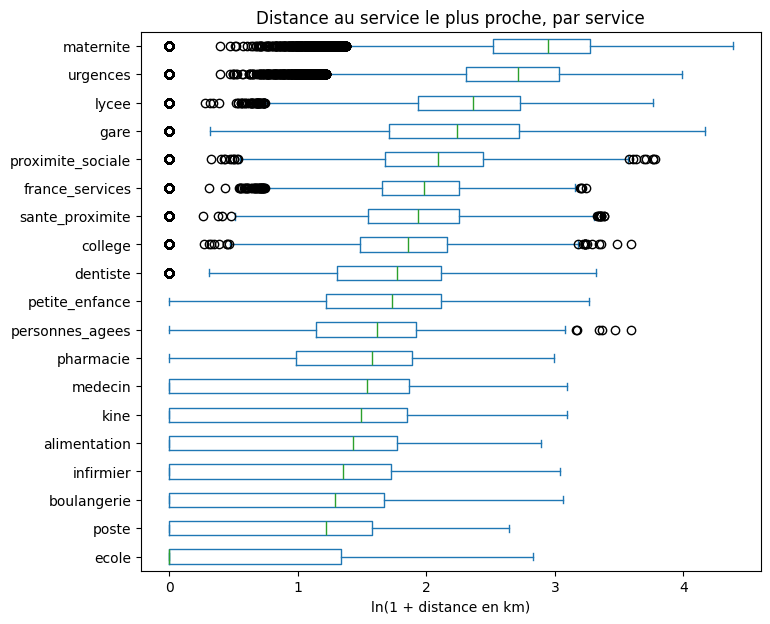

In [20]:
resume = dsc.resume_par_service(distances)
display(resume.sort_values("mediane_km", ascending=False))

ordre = distances.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 7))
np.log1p(distances[ordre]).plot.box(vert=False, ax=ax)
ax.set_xlabel("ln(1 + distance en km)")
ax.set_title("Distance au service le plus proche, par service")
fig.savefig(FIGURES / "boites_distances.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.2 La population éloignée

**Objectif.** Jusqu’ici, on a compté des communes ; or ce qui nous intéresse vraiment, ce sont les habitants. La France compte énormément de petites communes très peu peuplées : dire que « beaucoup de communes sont loin d’un service » donne l’impression d’un problème massif, alors qu’elles peuvent ne regrouper qu’une petite partie de la population. Cette étape additionne donc la population des communes situées à plus de 5, 10 ou 20 km d’un service et la rapporte à la population totale, pour obtenir la part des habitants concernés. On obtient ainsi le nombre de personnes touchées.

**Ce que fait le code.** Pour chaque service et chaque seuil, `dsc.part_population_eloignee` additionne la population des communes dont la distance dépasse le seuil, et divise par la population totale. Une commune équipée a une distance de 0, elle n'est jamais comptée comme éloignée.

Mais 2 biais sont à prendre en compte ici: 
- D’abord, tous les habitants d’une commune sont supposés vivre à son centre : ils reçoivent donc la même distance au service, alors que dans une grande commune certains vivent près de l’équipement et d’autres bien plus loin, l’erreur pouvant aller dans les deux sens selon les communes.
- Ensuite, toute la population est comptée pour chaque service, alors que tous les habitants n’ont pas besoin de tous les services : les enfants pour l’école, les femmes en âge de procréer pour la maternité, les personnes âgées pour l’hébergement. Les pourcentages obtenus mesurent donc la population exposée à l’éloignement d’un service, et non le nombre de personnes qui en auraient réellement besoin ; la population par âge et par sexe de chaque commune permettrait d’affiner ce calcul dans un prolongement du projet.

In [21]:
pop = base.set_index("code")["population"]
eloignee = dsc.part_population_eloignee(distances, pop, SEUILS_KM) # Remember seuils_km etaient les 5, 10, 20 definis en debut de ce notebook
display(eloignee.sort_values(eloignee.columns[0], ascending=False))

# Dans le tableau on lit for eg que 
# 53,07 % des habitants vivent dans une commune dont le centre est à plus de 5 km d’une maternité.
# La formule ici étant : part = (somme des populations des communes plus loin que le seuil) ÷ (population totale) × 100

,> 5 km,> 10 km,> 20 km
maternite,53.07,35.80,13.87
urgences,48.56,29.48,7.03
lycee,32.69,15.21,1.72
france_services,29.92,5.68,0.03
gare,29.91,14.24,3.59
proximite_sociale,27.46,9.26,0.50
sante_proximite,21.17,4.45,0.12
college,15.79,1.87,0.03
dentiste,10.96,1.65,0.01
petite_enfance,10.37,1.89,0.03


### 8.3 L'indice : distribution et communes les plus isolées

**Objectif.** Lire la distribution de l'indice principal (poids égaux) et identifier les communes les plus isolées.

**Ce que fait le code.**
1. Affiche les **quantiles** de l'indice (`describe`), puis son **histogramme**. 
2. Liste les **20 communes ou arrondissements** à l'indice le plus élevé, avec leur population et leur surface.

Un indice négatif veut dire que la commune est mieux desservie que la commune moyenne.


,indice (egaux)
count,34788.000
mean,-0.000
std,0.712
min,-2.160
1%,-1.941
10%,-1.073
25%,-0.414
50%,0.161
75%,0.522
90%,0.778


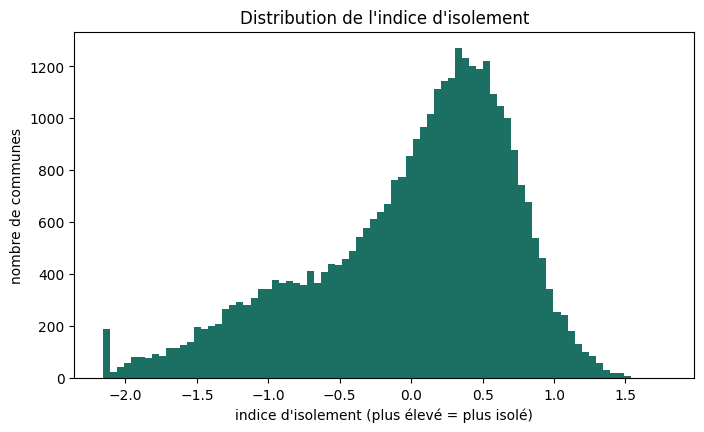

,nom,population,surface_km2,indice
code,,,,
64542,Urdos,71,36.661530,1.785700
2B153,Manso,116,121.254632,1.762382
64136,Borce,112,58.272540,1.692086
05064,La Chapelle-en-Valgaudémar,120,127.505850,1.579194
09100,Couflens,100,56.355883,1.553541
38375,Saint-Christophe-en-Oisans,99,237.506235,1.536146
21237,Échalot,93,27.665546,1.535967
64316,Larrau,179,126.986982,1.528728
51371,Moivre,54,22.175960,1.526823


In [22]:
indice = indices[INDICE_PRINCIPAL]
display(dsc.decrire_indice(indice).to_frame(f"indice ({INDICE_PRINCIPAL})"))

fig, ax = plt.subplots(figsize=(8, 4.5))
indice.plot.hist(bins=80, ax=ax, color="#1B6F63")
ax.set_xlabel("indice d'isolement (plus élevé = plus isolé)")
ax.set_ylabel("nombre de communes")
ax.set_title("Distribution de l'indice d'isolement")
fig.savefig(FIGURES / "histogramme_indice.png", dpi=150, bbox_inches="tight")
plt.show()

display(dsc.communes_les_plus_isolees(base, indice, n=20))

Nous voyons que les communes les plus isolées ont de faible population, c'est un profil attendu car très peu d'habitants signifie aussi peu d'équipements en place

## 9. Cartes

### 9.1 La carte de l'indice

**Objectif.** Voir **où** se concentre l'isolement (hypothèse H3).

**Ce que fait le code.**
1. Joint l'indice aux polygones `geo` (sur le code commune) pour obtenir une table cartographique.
2. Trace une **carte choroplèthe** : chaque commune est coloriée selon son indice, du clair (proche des services) au foncé (isolé).
3. **Borne l'échelle de couleurs** entre les centiles 2 et 98 
4. Enregistre l'image dans `figures/carte_indice.png`.


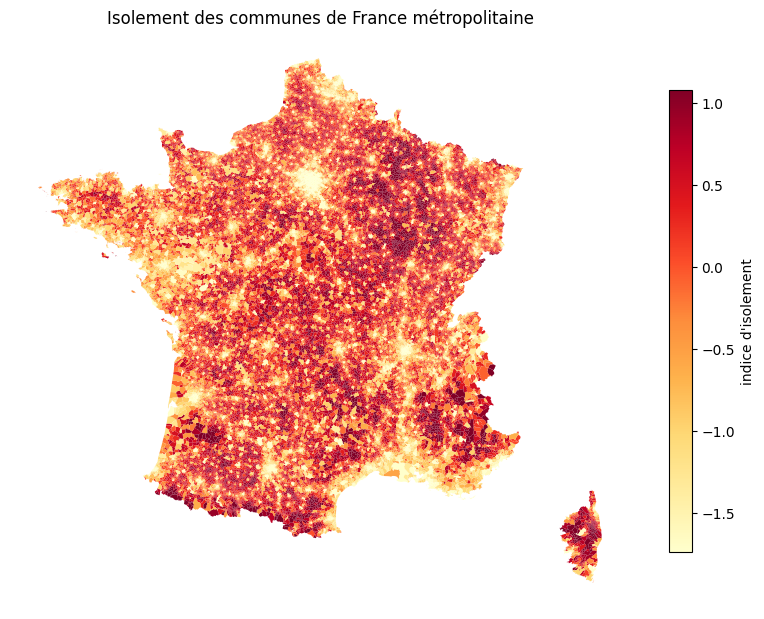

In [23]:
carte = geo.merge(indices.reset_index(), on="code")

vmin, vmax = carte[INDICE_PRINCIPAL].quantile([0.02, 0.98])
fig, ax = plt.subplots(figsize=(10, 10))
carte.plot(column=INDICE_PRINCIPAL, cmap="YlOrRd", vmin=vmin, vmax=vmax, linewidth=0, ax=ax,
           legend=True, legend_kwds={"shrink": 0.6, "label": "indice d'isolement"})
ax.set_axis_off()
ax.set_title("Isolement des communes de France métropolitaine")
fig.savefig(FIGURES / "carte_indice.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
print("Part des communes à indice > 0 :", f"{(indice > 0).mean():.2%}")
#.mean car car on veut calculer le % et (indice > 0) va donner le nombre dont l'indice est sup à 1 vu que c'est 1 si l'indice est sup à 0 et 0 sinon et moyenne dicise par le total 
print("Médiane :", round(indice.median(), 3), "| moyenne :", round(indice.mean(), 3)) # la moyenne est proche de 0 du fait de la standardisation
pop = base.set_index("code")["population"]
print("Part de la population vivant dans une commune à indice > 0 :",
      f"{pop[indice > 0].sum() / pop.sum():.1%}")

Part des communes à indice > 0 : 59.01%
Médiane : 0.161 | moyenne : -0.0
Part de la population vivant dans une commune à indice > 0 : 9.9%


### 9.2 Les cartes par service

**Objectif.** Voir **quel service manque, et où** : l'indice résume 19 services, mais deux communes de même indice peuvent manquer de services très différents.

**Ce que fait le code.** Pour les six services de `SERVICES_CARTES`, trace une petite carte de `ln(1 + distance)`. Chaque carte a sa propre échelle de couleurs (bornée au 98ᵉ centile), puisque les distances d'une gare et d'une boulangerie n'ont pas la même ampleur. L'image est enregistrée dans `figures/cartes_services.png`.


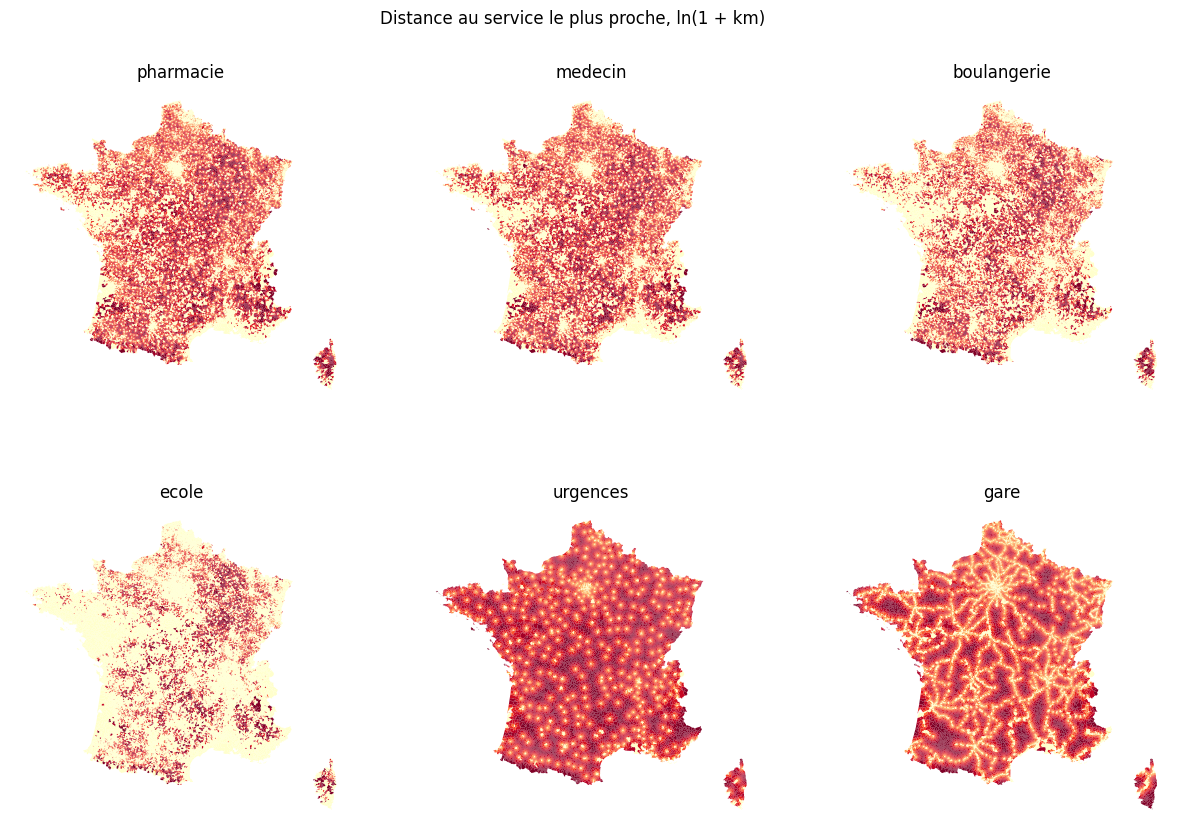

In [25]:
carte_services = geo.merge(distances.reset_index(), on="code")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, service in zip(axes.ravel(), SERVICES_CARTES):
    valeurs = np.log1p(carte_services[service])
    carte_services.assign(valeur=valeurs).plot(
        column="valeur", cmap="YlOrRd", vmin=0, vmax=float(valeurs.quantile(0.98)),
        linewidth=0, ax=ax, legend=False)
    ax.set_axis_off()
    ax.set_title(service)
fig.suptitle("Distance au service le plus proche, ln(1 + km)", y=0.94)
fig.savefig(FIGURES / "cartes_services.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Isolement et densité (hypothèse H2)

**Objectif.** Tester l'hypothèse : **plus une commune est peu dense, plus elle est isolée.** 

**Pourquoi la corrélation de Spearman et pas celle de Pearson.** Pearson mesure une relation en ligne droite entre les valeurs. La densité est très asymétrique, donc quelques communes écraseraient tout. Spearman **remplace chaque valeur par son rang** (la 1ʳᵉ, la 2ᵉ, la 3ᵉ…) puis calcule la corrélation des rangs : elle ne dépend ni de l'échelle ni des valeurs extrêmes, et détecte toute relation qui va dans le même sens, droite ou courbe. Elle vaut −1 (sens opposés), 0 (aucun lien) ou +1 (même ordre).

**Entrées.** `indice` (poids égaux, une valeur par commune) et la colonne `densite` de `base` (habitants par km²).

**Ce que fait le code.**
1. Charge le module `analyse` et aligne `indice` et `dens` sur les mêmes codes commune.
2. Calcule le Spearman entre les deux, sur les communes qui ont une densité. La p-value mesure la probabilité d'observer un lien aussi fort par hasard : avec 34 000 communes, elle sera minuscule pour presque tout lien, donc **la valeur de ρ compte plus que la p-value**.
3. Range les communes en 5 classes de densité de même effectif (quintiles : 20 % des communes les moins denses, etc.) et compare l'indice entre classes avec le **test de Kruskal-Wallis**. Ce test regarde si l'indice est distribué de la même manière dans tous les groupes. Sa **taille d'effet ε²** (de 0 à 1) dit si l'écart est grand (Un ε² de 0,3 voudrait dire que la densité explique environ 30 % de la variation des rangs de l’indice).
4. Trace deux graphiques : un nuage de points (log de la densité en abscisse, indice en ordonnée) et des boîtes à moustaches par classe de densité (les classes étant définies par les calculs précédents).


Spearman indice / densité : rho = -0.843  (n = 34,788, p = 0)
Kruskal-Wallis : H = 23639, p = 0, taille d'effet epsilon2 = 0.680


,communes,mediane,q25,q75
g,,,,
1 ( les 20% les moins dense),6958,0.718,0.532,0.897
2,6957,0.431,0.241,0.602
3,6958,0.187,-0.052,0.375
4,6957,-0.156,-0.497,0.085
5 (les 20% les plus dense),6958,-0.978,-1.364,-0.561


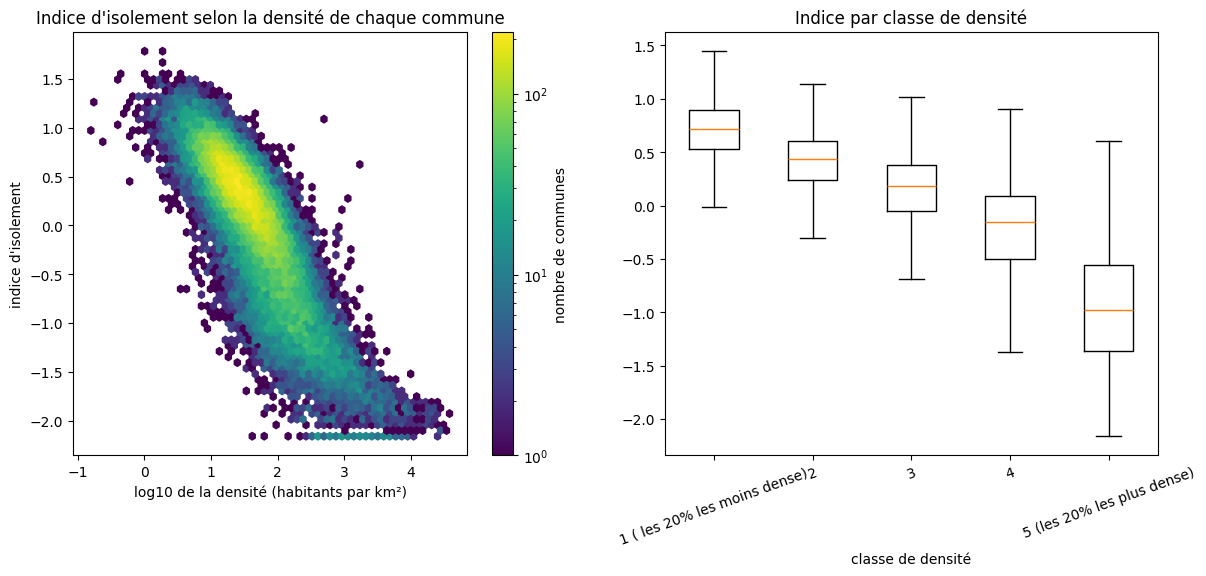

In [26]:
import analyse as an

dens = base.set_index("code")["densite"]
indice_a = indice.reindex(dens.index)

res_dens = an.correlation_spearman(indice_a, dens)
print(f"Spearman indice / densité : rho = {res_dens['rho']:.3f}  (n = {res_dens['n']:,}, p = {res_dens['p_value']:.2g})")

NOMS_DENSITE = ["1 ( les 20% les moins dense)", "2", "3", "4", "5 (les 20% les plus dense)"]
classe_densite = pd.qcut(dens.rank(method="first"), 5, labels=NOMS_DENSITE)
res_kw, tab_dens = an.comparer_groupes(indice_a, classe_densite)
print(f"Kruskal-Wallis : H = {res_kw['H']:.0f}, p = {res_kw['p_value']:.2g}, taille d'effet epsilon2 = {res_kw['epsilon2']:.3f}")
display(tab_dens)

ok = dens.notna() & (dens > 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
hb = axes[0].hexbin(np.log10(dens[ok]), indice_a[ok], gridsize=60, bins="log", cmap="viridis", mincnt=1)
axes[0].set_xlabel("log10 de la densité (habitants par km²)")
axes[0].set_ylabel("indice d'isolement")
axes[0].set_title("Indice d'isolement selon la densité de chaque commune")
fig.colorbar(hb, ax=axes[0], label="nombre de communes")
groupes_d = [indice_a[classe_densite == c].dropna() for c in NOMS_DENSITE]
axes[1].boxplot(groupes_d, showfliers=False)
axes[1].set_xticks(range(1, len(NOMS_DENSITE) + 1))
axes[1].set_xticklabels(NOMS_DENSITE)
axes[1].set_xlabel("classe de densité")
axes[1].set_title("Indice par classe de densité")
axes[1].tick_params(axis="x", rotation=20)
fig.savefig(FIGURES / "densite_indice.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Isolement et revenu (hypothèse H4)

### 11.1 Ajouter le revenu médian

**Objectif.** Disposer du **niveau de vie médian** de chaque commune (indicateur `MED_SL` de Filosofi 2023).

**Particularité du fichier.** Il est en **format long** : une ligne par couple (territoire, indicateur), avec tous les niveaux géographiques mélangés. Il contient plusieurs centaines de milliers de lignes, dont la plupart n'ont pas de valeur car ce sont des indicateurs non publiés à l'échelle communale (pour une petite commune, si on la communique, on pourra aisement deviner so le secret statistique exige de pas publier). Il faut donc filtrer sur les communes et les arrondissements municipaux qui nous interessent.

**Ce que fait le code.**
1. `an.lire_revenu` ne garde que les lignes dont le type de territoire est une commune (`COM`) ou un arrondissement (`ARM`), et l'indicateur `MED_SL`. Les valeurs absentes (secret statistique `s`, donnée manquante `vm`) deviennent des cases vides, et les codes sont remis sur 5 caractères.
2. `an.fusionner_revenu` joint le revenu à la base par **jointure à gauche** : aucune commune de la base ne disparaît, celles sans revenu restent avec une case vide. Un **journal** compte les communes sans revenu et les codes du fichier absents de la base.


In [27]:
FICHIER_REVENU = RAW / "Revenus.csv"

revenu = an.lire_revenu(FICHIER_REVENU)
base_rev, journal_rev = an.fusionner_revenu(base, revenu)
print("Journal de la fusion du revenu :", journal_rev)
print(f"Part des communes sans revenu : {journal_rev['communes_sans_revenu'] / journal_rev['communes_base']:.1%}")

revenu_s = base_rev.set_index("code")["revenu_median"]
display(revenu_s.describe().round(0).to_frame("niveau de vie médian (€)"))

Journal de la fusion du revenu : {'communes_base': 34788, 'communes_sans_revenu': 3976, 'codes_revenu_hors_base': 27}
Part des communes sans revenu : 11.4%


,niveau de vie médian (€)
count,30812.0
mean,26270.0
std,3541.0
min,12420.0
25%,24090.0
50%,25780.0
75%,27840.0
max,62730.0


### 11.2 Les communes sans revenu sont-elles différentes ?

**Objectif.** Vérifier si les valeurs manquantes créent un **biais**. Le secret statistique fait qu'on ne connait pas les valeurs pour les petites communes, qui sont souvent isolées : si on les écarte, on risque de sous-estimer le lien entre isolement et revenu.

**Ce que fait le code.** Sépare les communes en deux groupes (avec revenu, sans revenu), compare l'indice d'isolement et la population de chacun avec le test de Kruskal-Wallis (ici entre deux groupes), puis donne la part de la **population** concernée.


In [28]:
a_revenu = pd.Series(np.where(revenu_s.notna(), "avec revenu", "sans revenu"), index=revenu_s.index)

res_man, tab_man = an.comparer_groupes(indice.reindex(a_revenu.index), a_revenu)
print(f"Kruskal-Wallis (indice, avec/sans revenu) : p = {res_man['p_value']:.2g}, epsilon2 = {res_man['epsilon2']:.3f}")
display(tab_man)

pop_s = base.set_index("code")["population"]
print(f"Part de la population dans les communes sans revenu : "
      f"{pop_s[a_revenu == 'sans revenu'].sum() / pop_s.sum():.2%}")

Kruskal-Wallis (indice, avec/sans revenu) : p = 0, epsilon2 = 0.164


,communes,mediane,q25,q75
g,,,,
avec revenu,30812,0.070,-0.524,0.428
sans revenu,3976,0.718,0.513,0.912


Part de la population dans les communes sans revenu : 0.44%


Les 3 976 communes sans revenu médian publié (11,4 %) sont nettement plus isolées que les autres (indice médian de 0,72 contre 0,07 ; test de Kruskal-Wallis, p < 0,001, ε² = 0,16, effet fort). L’analyse du revenu porte donc sur un échantillon moins isolé que la population des communes et donc ses conclusions ne s’appliquent pas aux communes les plus isolées.

### 11.3 Le lien entre isolement et revenu

**Objectif.** Mesurer si les communes plus isolées sont plus pauvres (ou plus riches), et si l'effet est grand.

**Ce que fait le code.**
1. **Spearman** entre l'indice et le revenu médian, sur les communes qui ont un revenu.
2. **Quintiles de revenu** : 5 groupes de même effectif, du revenu le plus bas au plus haut, puis **Kruskal-Wallis** et sa taille d'effet ε² (voir le §10), avec l'indice médian de chaque groupe.
3. Un **diagramme en boîtes** de l'indice par quintile de revenu.

Un ρ négatif voudrait dire « plus isolé, plus pauvre » ; positif, « plus isolé, plus riche ». Une corrélation **n'est pas une causalité** : elle dit que les deux vont ensemble, pas que l'un provoque l'autre.

Spearman indice / revenu : rho = -0.216  (n = 30,812, p = 0)
Kruskal-Wallis : H = 1554, p = 0, epsilon2 = 0.050


,communes,mediane,q25,q75
g,,,,
1 (plus bas),6163,0.285,-0.576,0.621
2,6162,0.202,-0.343,0.491
3,6162,0.132,-0.328,0.431
4,6162,0.010,-0.494,0.337
5 (plus haut),6163,-0.233,-0.782,0.147


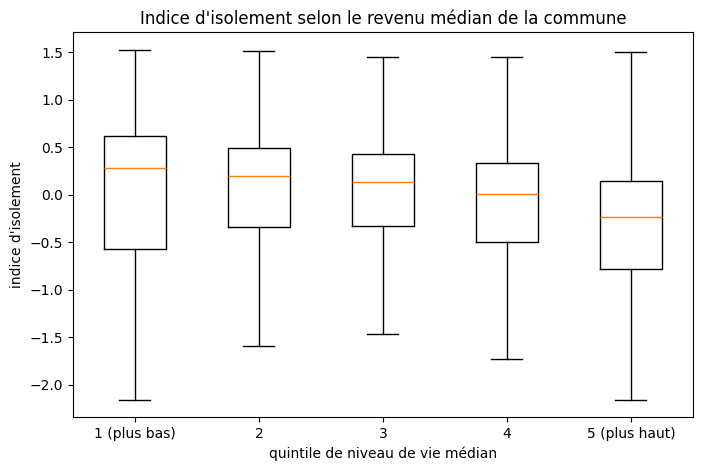

In [29]:
indice_r = indice.reindex(revenu_s.index)

res_rev = an.correlation_spearman(indice_r, revenu_s)
print(f"Spearman indice / revenu : rho = {res_rev['rho']:.3f}  (n = {res_rev['n']:,}, p = {res_rev['p_value']:.2g})")

NOMS_REVENU = ["1 (plus bas)", "2", "3", "4", "5 (plus haut)"]
quintile_revenu = pd.qcut(revenu_s.rank(method="first"), 5, labels=NOMS_REVENU)
res_kw_rev, tab_rev = an.comparer_groupes(indice_r, quintile_revenu)
print(f"Kruskal-Wallis : H = {res_kw_rev['H']:.0f}, p = {res_kw_rev['p_value']:.2g}, epsilon2 = {res_kw_rev['epsilon2']:.3f}")
display(tab_rev)

fig, ax = plt.subplots(figsize=(8, 5))
groupes = [indice_r[quintile_revenu == q].dropna() for q in NOMS_REVENU]
ax.boxplot(groupes, showfliers=False)
ax.set_xticks(range(1, len(NOMS_REVENU) + 1))
ax.set_xticklabels(NOMS_REVENU)
ax.set_xlabel("quintile de niveau de vie médian")
ax.set_ylabel("indice d'isolement")
ax.set_title("Indice d'isolement selon le revenu médian de la commune")
fig.savefig(FIGURES / "revenu_indice.png", dpi=150, bbox_inches="tight")
plt.show()

1. Plus le niveau de vie médian de la commune est élevé, moins elle tend à être isolée. Les communes les plus modestes sont un peu plus isolées que la moyenne (médiane positive), les plus aisées sont mieux desservies (médiane négative).

2. L’écart s’accentue en haut de l’échelle. Les écarts entre quintiles successifs sont de 0,08, 0,07, 0,12 puis 0,24. C’est surtout le cinquième des communes les plus aisées qui se détache.

3. L’effet reste modeste. Entre le premier et le dernier quintile, la médiane passe de 0,29 à −0,23, soit environ 0,5 point d’indice. Mais les boîtes se chevauchent largement : dans chaque quintile, on trouve des communes très isolées et des communes très bien desservies, avec des moustaches presque identiques (de −2 à +1,5). Ça rejoint le ρ de Spearman de −0,22 et l'ε² de 0,05, un lien faible à moyen. Le revenu ne permet pas de prédire l’isolement d’une commune donnée.

4. Les communes les plus modestes sont les plus hétérogènes. La boîte du quintile 1 est la plus large (de −0,58 à +0,62) : parmi elles, on trouve à la fois des communes très isolées et des communes bien desservies, par exemple des quartiers de villes. Le quintile 5 est plus resserré.

### 11.4 Effet potentiel de la densité

**Objectif.** Vérifier que le lien observé entre isolement et revenu **n'est pas simplement un effet de la densité**. La densité est liée à l'isolement (§10) *et* au revenu (les villes ont des revenus médians différents des campagnes). Une variable qui influence les deux à la fois peut créer un lien apparent entre elles : c'est un **facteur de confusion**.

**Ce que fait le code.**
1. Calcule la corrélation de Spearman entre le revenu et la densité.
2. Refait la corrélation indice / revenu **séparément dans chacune des 5 classes de densité**. Dans chaque classe, la densité varie peu : si le lien persiste, il ne vient pas que de la densité.

Ainsi, si ρ va vers 0 dans les classes, le lien global était surtout dû à la densité. S'il garde le même signe et une taille comparable, l'isolement a un lien propre avec le revenu.

In [30]:
res_rev_dens = an.correlation_spearman(revenu_s, dens.reindex(revenu_s.index))
print(f"Spearman revenu / densité : rho = {res_rev_dens['rho']:.3f}  (n = {res_rev_dens['n']:,})")

classe_d = classe_densite.reindex(revenu_s.index)
lignes = {c: an.correlation_spearman(indice_r[classe_d == c], revenu_s[classe_d == c]) for c in NOMS_DENSITE}
print("\nCorrélation indice / revenu à l'intérieur de chaque classe de densité :")
display(pd.DataFrame(lignes).T.round(3))

Spearman revenu / densité : rho = 0.347  (n = 30,812)

Corrélation indice / revenu à l'intérieur de chaque classe de densité :


,rho,p_value,n
1 ( les 20% les moins dense),-0.071,0.000,3968.0
2,0.006,0.663,6172.0
3,0.052,0.000,6790.0
4,0.153,0.000,6928.0
5 (les 20% les plus dense),0.294,0.000,6954.0


Le lien global entre isolement et revenu (ρ = −0,22) est surtout un effet de la densité : les territoires peu denses sont à la fois plus isolés et plus modestes. À densité comparable, le lien disparaît dans les zones rurales et devient positif dans les zones denses. C’est ce qu’on appelle un facteur de confusion : la densité influence les deux variables et crée un lien apparent entre elles.

## 12. Typologie : quels types d'isolement ?

**Objectif.** L'indice dit *à quel point* une commune est isolée, pas *de quoi*. Deux communes de même indice peuvent manquer de services très différents. On cherche donc des **profils types** : des groupes de communes qui se ressemblent par la manière dont elles sont éloignées des services.

**Méthode.** On part des 19 écarts standardisés `z` de chaque commune (§7). Le **k-means** forme `k` groupes en répétant deux étapes : rattacher chaque commune au centre de groupe le plus proche, puis recalculer chaque centre comme la moyenne de son groupe. Il faut fixer `k` à l'avance. Pour le choisir, on regarde deux indicateurs :
- l'**inertie** (somme des carrés des écarts aux centres) : elle baisse toujours quand `k` augmente ; on cherche le « coude » où elle cesse de baisser vite ;
- la **silhouette** (de −1 à 1) : elle dit si les groupes sont bien séparés ; plus elle est haute, mieux c'est.

On choisit `k` par jugement, entre 4 et 6 pour rester lisible, en s'aidant de ces deux courbes.

**Ce que fait le code.**
1. `an.choisir_k` calcule inertie et silhouette (sur un échantillon de 5 000 communes, pour aller vite) pour k de 2 à 8, et on les trace.
2. On fixe `N_GROUPES`, puis `an.typologie` lance le k-means et **numérote les groupes du mieux desservi (0) au moins bien desservi** (la numérotation brute du k-means est aléatoire). Elle calcule aussi le plan des deux premières composantes principales (PC1, PC2) pour dessiner les groupes.
3. On calcule le **profil moyen de chaque groupe** (la moyenne des `z` de chaque service) et on l'affiche en carte de chaleur : rouge = plus éloigné que la moyenne, bleu = plus proche.
4. Un tableau résume chaque groupe : nombre de communes, part de la population, indice, densité et revenu médians.
5. Une **carte** colorie chaque commune selon son groupe.


In [31]:
%pip install --upgrade threadpoolctl

,inertie,silhouette
k,,
2,417308.247,0.369
3,363681.996,0.199
4,333246.607,0.160
5,316938.888,0.146
6,301813.280,0.141
7,289396.783,0.145
8,278674.525,0.112


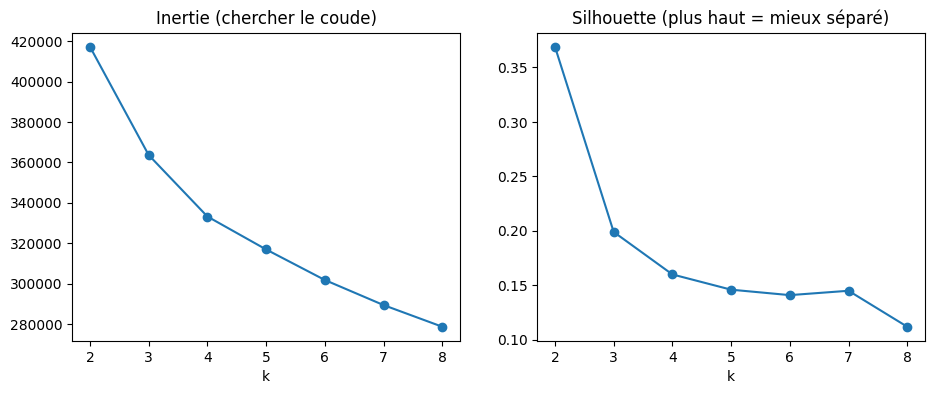

In [32]:
cout_k = an.choisir_k(z)
display(cout_k)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cout_k["inertie"].plot(marker="o", ax=axes[0], title="Inertie (chercher le coude)")
cout_k["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette (plus haut = mieux séparé)")
fig.savefig(FIGURES / "choix_k.png", dpi=150, bbox_inches="tight")
plt.show()

Variance expliquée par PC1 et PC2 : [0.516 0.093]


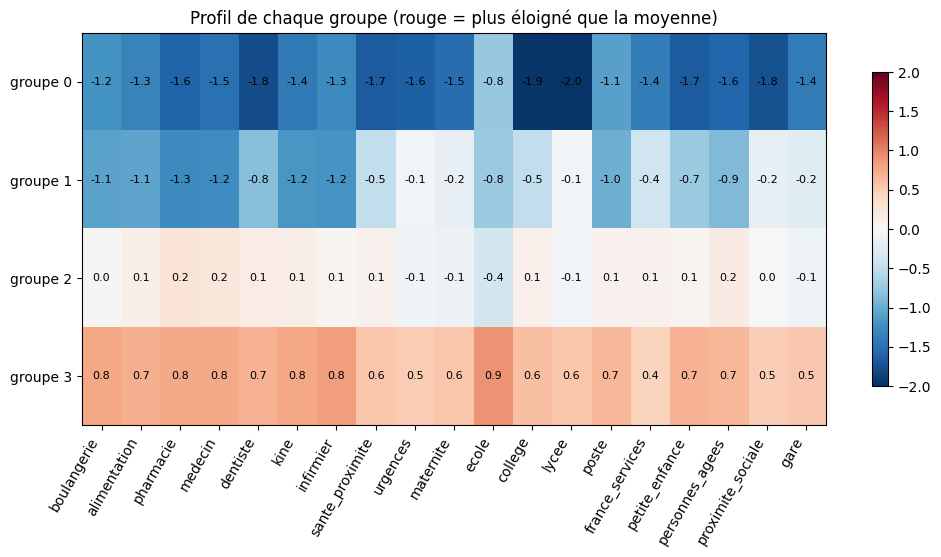

,communes,part_population_%,indice_median,densite_mediane,revenu_median
groupe,,,,,
0,3057,63.9,-1.44,534.9,25970.0
1,6256,20.5,-0.71,112.6,26005.0
2,12695,11.5,0.08,49.9,26370.0
3,12780,4.1,0.62,15.6,24900.0


In [33]:
N_GROUPES = 4       
res_typo, profils, var_pca = an.typologie(z, N_GROUPES)
print(f"Variance expliquée par PC1 et PC2 : {var_pca.round(3)}")

# Profils : moyenne des z de chaque service dans chaque groupe
fig, ax = plt.subplots(figsize=(12, 3.5 + 0.4 * N_GROUPES))
im = ax.imshow(profils, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(profils.shape[1]))
ax.set_xticklabels(profils.columns, rotation=60, ha="right")
ax.set_yticks(range(N_GROUPES))
ax.set_yticklabels([f"groupe {g}" for g in profils.index])
for i in range(profils.shape[0]):
    for j in range(profils.shape[1]):
        ax.text(j, i, f"{profils.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("Profil de chaque groupe (rouge = plus éloigné que la moyenne)")
fig.colorbar(im, shrink=0.8)
fig.savefig(FIGURES / "profils_groupes.png", dpi=150, bbox_inches="tight")
plt.show()

# Résumé par groupe
g = res_typo["groupe"]
resume_groupes = pd.DataFrame({
    "communes": g.value_counts().sort_index(),
    "part_population_%": (pop_s.groupby(g).sum() / pop_s.sum() * 100).round(1),
    "indice_median": indice.groupby(g).median().round(2),
    "densite_mediane": dens.groupby(g).median().round(1),
    "revenu_median": revenu_s.groupby(g).median().round(0),
})
display(resume_groupes)

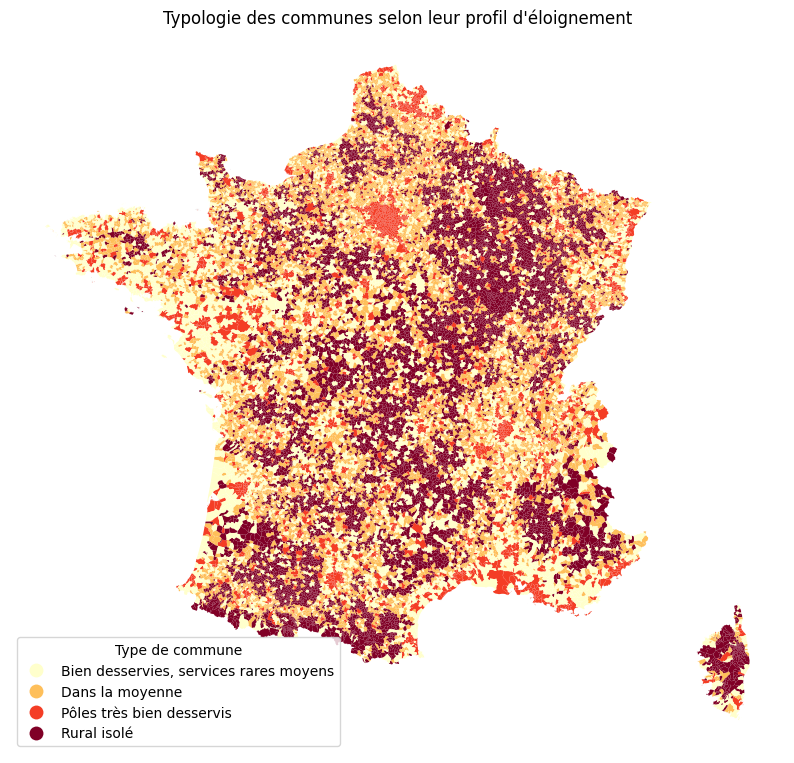

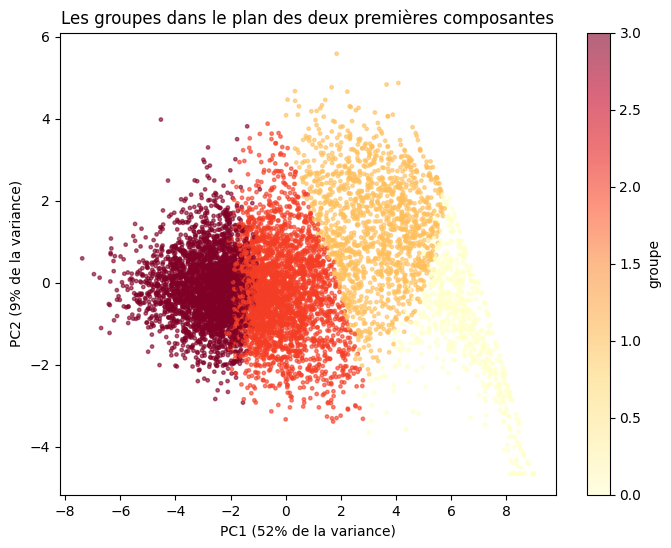

In [34]:
NOMS_GROUPES = {0: "Pôles très bien desservis", 1: "Bien desservies, services rares moyens",
                2: "Dans la moyenne", 3: "Rural isolé"}

carte_typo = geo.merge(res_typo.rename_axis("code").reset_index(), on="code")
carte_typo["type"] = carte_typo["groupe"].map(NOMS_GROUPES)

fig, ax = plt.subplots(figsize=(10, 10))
carte_typo.plot(column="type", categorical=True, cmap="YlOrRd", linewidth=0, ax=ax, legend=True,
                legend_kwds={"loc": "lower left", "title": "Type de commune"})
ax.set_axis_off()
ax.set_title("Typologie des communes selon leur profil d'éloignement")
fig.savefig(FIGURES / "carte_typologie.png", dpi=200, bbox_inches="tight")
plt.show()

# Plan PC1 x PC2 (échantillon de 8 000 communes pour la lisibilité)
echantillon = res_typo.sample(min(8000, len(res_typo)), random_state=0)
fig, ax = plt.subplots(figsize=(8, 6))
nuage = ax.scatter(echantillon["pc1"], echantillon["pc2"], c=echantillon["groupe"], cmap="YlOrRd", s=6, alpha=0.6)
ax.set_xlabel(f"PC1 ({var_pca[0]:.0%} de la variance)")
ax.set_ylabel(f"PC2 ({var_pca[1]:.0%} de la variance)")
ax.set_title("Les groupes dans le plan des deux premières composantes")
fig.colorbar(nuage, label="groupe")
fig.savefig(FIGURES / "plan_acp.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Autocorrélation spatiale (hypothèse H3)

**Objectif.** Tester que l'isolement est **groupé géographiquement** : les communes isolées sont-elles voisines les unes des autres, plutôt que dispersées au hasard ? 

**Le I de Moran global.** Pour chaque commune, on compare sa valeur à la moyenne de ses voisines. Le I vaut environ **0** si la répartition est aléatoire, tend vers **+1** si les valeurs semblables se regroupent, et vers **−1** si les valeurs opposées alternent. La significativité vient de **permutations** : on mélange la carte au hasard 199 fois, on calcule le I à chaque fois, et on regarde si notre valeur sort de la distribution obtenue.

**Qui est voisin ?** Les **8 communes les plus proches** (distance entre centres). Ce choix évite le problème des communes de tailles très différentes, avec très peu de voisines pour certaines et beaucoup pour d'autres.

**Les cartes LISA (I de Moran local).** On classe chaque commune en :
- **HH** : isolée, entourée de communes isolées (un « pôle » d'isolement) ;
- **LL** : bien desservie, entourée de communes bien desservies ;
- **HL / LH** : une commune isolée au milieu de communes bien desservies, ou l'inverse ;
- **ns** : pas de structure locale significative.

**Ce que fait le code.**
1. Récupère les coordonnées des centres, avec les mêmes codes que l'indice.
2. Calcule le I de Moran global de l'indice, puis un contrôle sur l'indice mélangé au hasard (qui doit donner I ≈ 0, ce qui valide la méthode).
3. Calcule les classes LISA, les compte, et trace la carte.


In [ ]:
%pip install esda libpysal

C:\Users\USER\anaconda3\Lib\site-packages\libpysal\weights\distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


I de Moran global (indice) : 0.594  (espérance sous le hasard -0.0000, p = 0.005)
Contrôle sur l'indice mélangé au hasard : I = -0.003


,communes
lisa,
ns,20322
HH,8052
LL,5432
LH,796
HL,186


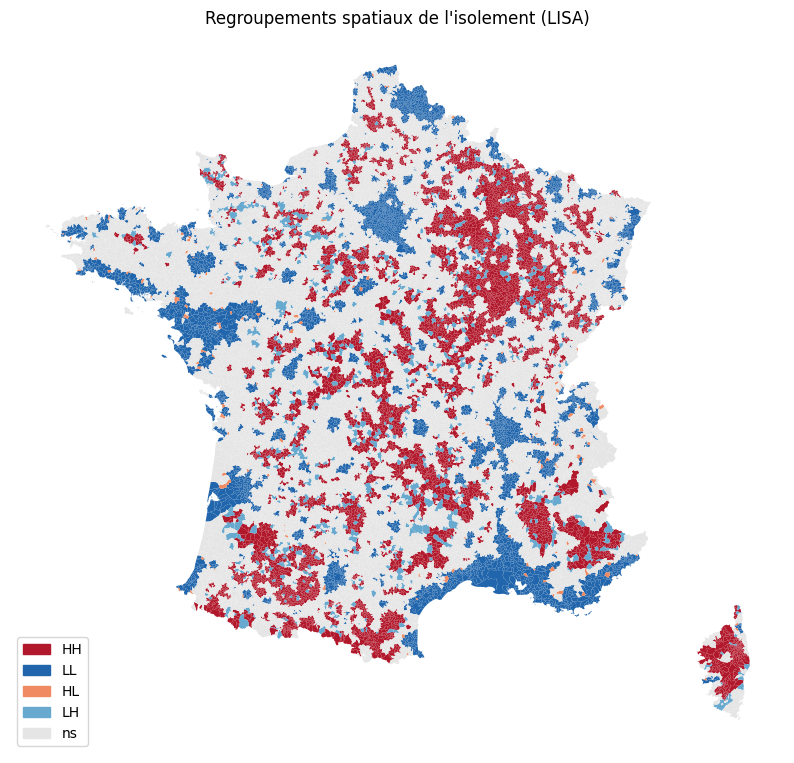

In [39]:
K_VOISINS = 8
lisa = None
try:
    xy = base.set_index("code").loc[indice.index, ["x", "y"]]

    moran = an.moran_global(indice, xy["x"], xy["y"], k=K_VOISINS)
    print(f"I de Moran global (indice) : {moran['I']:.3f}  (espérance sous le hasard {moran['esperance']:.4f}, p = {moran['p_sim']:.3g})")

    melange = pd.Series(indice.sample(frac=1, random_state=0).to_numpy(), index=indice.index)
    controle = an.moran_global(melange, xy["x"], xy["y"], k=K_VOISINS)
    print(f"Contrôle sur l'indice mélangé au hasard : I = {controle['I']:.3f}")

    lisa = an.moran_local(indice, xy["x"], xy["y"], k=K_VOISINS)
    display(lisa.value_counts().to_frame("communes"))

    from matplotlib.patches import Patch
    couleurs = {"HH": "#B2182B", "LL": "#2166AC", "HL": "#EF8A62", "LH": "#67A9CF", "ns": "#E5E5E5"}
    carte_l = geo.merge(lisa.rename_axis("code").reset_index(), on="code")
    fig, ax = plt.subplots(figsize=(10, 10))
    for classe, couleur in couleurs.items():
        carte_l[carte_l["lisa"] == classe].plot(color=couleur, linewidth=0, ax=ax)
    ax.legend(handles=[Patch(color=c, label=k) for k, c in couleurs.items()], loc="lower left")
    ax.set_axis_off()
    ax.set_title("Regroupements spatiaux de l'isolement (LISA)")
    fig.savefig(FIGURES / "carte_lisa.png", dpi=200, bbox_inches="tight")
    plt.show()
except ImportError as erreur:
    print("Section ignorée, bibliothèque manquante ")

## 14. Table finale

**Objectif.** Rassembler en un seul fichier tout ce qui sert à la suite : indice, rang en centile (% de communes plus isolées qu'elle , si =9 ca implique que plus isolée que 90 % des communes », donc dans les 10 % les plus isolées) , groupe de la typologie, classe LISA, population, densité, revenu.

**Ce que fait le code.** Construit le tableau (une ligne par commune), ajoute le **centile** de l'indice (« plus isolée que X % des communes »), qui est plus parlant qu'un z-score négatif ou positif, puis l'enregistre dans `data/processed/communes_analyse.parquet`.

In [40]:
final = base.set_index("code")[["nom", "population", "surface_km2", "densite"]].copy()
final["revenu_median"] = revenu_s
final["indice"] = indice
final["indice_centile"] = (indice.rank(pct=True) * 100).round(1)
final["groupe"] = res_typo["groupe"]
if lisa is not None:
    final["lisa"] = lisa

final.reset_index().to_parquet(PROCESSED / "communes_analyse.parquet", index=False)
print(f"Enregistré : {final.shape[0]:,} communes, {final.shape[1]} colonnes")
display(final.sort_values("indice", ascending=False).head(10))

Enregistré : 34,788 communes, 9 colonnes


,nom,population,surface_km2,densite,revenu_median,indice,indice_centile,groupe,lisa
code,,,,,,,,,
64542,Urdos,71,36.661530,1.936635,NaN,1.785700,100.0,3,HH
2B153,Manso,116,121.254632,0.956664,NaN,1.762382,100.0,3,HH
64136,Borce,112,58.272540,1.922003,NaN,1.692086,100.0,3,HH
05064,La Chapelle-en-Valgaudémar,120,127.505850,0.941133,NaN,1.579194,100.0,3,HH
09100,Couflens,100,56.355883,1.774438,NaN,1.553541,100.0,3,HH
38375,Saint-Christophe-en-Oisans,99,237.506235,0.416831,NaN,1.536146,100.0,3,HH
21237,Échalot,93,27.665546,3.361582,NaN,1.535967,100.0,3,HH
64316,Larrau,179,126.986982,1.409593,20970.0,1.528728,100.0,3,HH
51371,Moivre,54,22.175960,2.435069,NaN,1.526823,100.0,3,HH


## 15. Conclusion

### 15.1 Résumé des hypothèses

| Hypothèse | Résultat | Où le lire | Verdict |
|---|---|---|---|
| **H1** : la distribution des distances est très asymétrique | Médiane et moyenne très proches pour presque tous les services (maternité : 18,0 et 19,1 km ; pharmacie : 3,85 et 3,79 km). Pour la maternité, centile 99 = 46,9 km, maximum = 79,1 km. Seule l'école s'écarte (médiane 0, moyenne 1,38 km), car 61 % des communes en ont une. | §8.1 | **Non confirmée** : distribution resserrée, sans longue queue |
| **H2** : plus la commune est peu dense, plus elle est isolée | ρ de Spearman indice / densité = **−0,84** (n = 34 788). Kruskal-Wallis entre les 5 classes de densité : ε² = **0,68** (effet très fort). Indice médian : 0,72 (20 % les moins denses), 0,43, 0,19, −0,16, −0,98 (20 % les plus denses). | §10 | **Confirmée, très nettement** |
| **H3** : l'isolement est groupé géographiquement | I de Moran global = **0,594** (p ≤ 0,005 avec 199 permutations : aucune permutation n'atteint la valeur observée), alors que le même calcul sur l'indice mélangé au hasard donne −0,003, soit 0 en pratique, ce qui valide la méthode. L'analyse locale (LISA) classe 23,1 % des communes en grappes d'isolement (HH), 15,6 % en grappes de bonne desserte (LL) et seulement 2,8 % en îlots contrastés (LH/HL). 58,4 % des communes ne sont pas significatives. | §13 | **Confirmée** : l'isolement est fortement regroupé dans l'espace |
| **H4** : lien entre isolement et revenu | ρ indice / revenu = **−0,22** (n = 30 812), ε² = **0,05** (effet faible). À densité comparable : ρ = −0,07 ; 0,01 ; 0,05 ; 0,15 ; 0,29 (des classes les moins denses aux plus denses). | §11.3 et §11.4 | **Partiellement confirmée** : lien global faible, surtout dû à la densité, de signe variable |

### 15.2 Chiffres clés

- 34 788 communes et arrondissements de métropole, 66,2 millions d'habitants, 531 417 équipements regroupés en 19 services.
- 10 806 communes (31 %) n'ont aucun équipement du panier.
- **59,0 % des communes ont un indice supérieur à 0** (plus isolées que la commune moyenne), mais elles ne regroupent que **9,9 % de la population** : les communes isolées sont nombreuses mais peu peuplées.
- Maternité : **53,1 %** des habitants vivent à plus de 5 km (à vol d'oiseau) de la plus proche, **35,8 %** à plus de 10 km, **13,9 %** à plus de 20 km. Urgences : 48,6 %, 29,5 % et 7,0 %. Lycée : 32,7 %, 15,2 % et 1,7 %.
- À l'inverse, seuls 0,46 % des habitants sont à plus de 5 km d'une école et 1,3 % d'une poste.
- Le classement des communes est stable : corrélation de Spearman ≥ 0,941 entre tous les indices testés.
- Les 20 communes les plus isolées sont de très petites communes (de 5 à 179 habitants) des Pyrénées, des Alpes, de Corse, du Massif central, des Landes et des plaines de Champagn ots séparés du reste du territoire.th|
| `figures/*.png` | graphiques et cartes |

In [8]:
%pip install xlsxwriter
!dir data\processed


   ---------------------------------------- 0.0/180.6 kB ? eta -:--:--
   -- ------------------------------------- 10.2/180.6 kB ? eta -:--:--
   -- ------------------------------------- 10.2/180.6 kB ? eta -:--:--
   -------- ------------------------------ 41.0/180.6 kB 245.8 kB/s eta 0:00:01
   ------------------------------------ - 174.1/180.6 kB 952.6 kB/s eta 0:00:01
   -------------------------------------- 180.6/180.6 kB 906.1 kB/s eta 0:00:00
 Volume in drive C has no label.
 Volume Serial Number is B09E-4805

 Directory of C:\Users\USER\isolement-communes\data\processed

10/21/2026  06:46 PM    <DIR>          .
10/21/2026  01:08 PM    <DIR>          ..
10/28/2026  02:58 PM         1,867,355 communes_analyse.parquet
10/27/2026  11:13 PM         7,526,978 communes_distances.parquet
10/27/2026  11:13 PM           295,966 communes_presence.parquet
10/27/2026  11:13 PM         2,649,651 indices.parquet
               4 File(s)     12,339,950 bytes
               2 Dir(s)   9,896,2

In [9]:
!python app/construire_application.py --moran-i 0.594 --moran-controle -0.003 --moran-p 0.005

Application : C:\Users\USER\isolement-communes\app\isolement_communes.html  (12.1 Mo)
Classeur    : C:\Users\USER\isolement-communes\app\isolement_communes.xlsx  (6.5 Mo)


C:\Users\USER\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\USER\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
